# Simulador de janelas operacionais, bloco 15/9, Mar do Norte

**Intruções e Notas**: Este colab cria 15 janelas operacionais diferentes baseadas em cinco poços do bloco 15/9 do **Mar do Norte**, calibradas contra os LOT reais do Sodir e conferidas contra o peso de lama que cada poço realmente usou.


**Antes de rodar:** suba estes 4 arquivos pela barra de **Arquivos** (ícone de
pasta, à esquerda) para dentro desta sessão do Colab:

- `sonico.csv`
- `cabecalho.csv`
- `lama.csv`
- `lot.csv`

Neles estão contido os dados contidos nas bases de dados públicas:

- https://factpages.sodir.no/en/wellbore/PageView/With/Wdss/45
- https://zenodo.org/records/4351156#.YXhFTBrMJPb



**Como as janelas foram criadas**:

Tem uma célula de cálculo com todas as contas e equacionamentos. Nem todos são os mesmo da versão anterior do simulador. Tiveram que ser feitas alterações para calcular as janelas operacionais (Majoritariamente no calculo do gradiente de poros quanto ao expoente de Eaton - Veja nos comentários do código)

Todos os cálculos são feitos da forma de 3 **Variantes**

- **A**: Parâmetros genéricos da literatura pra poços ultraprofundos clássicos
- **B**: Parametros calibrados para assemelhar os resultados da janela com os dados da lama de perfuração advindos da base de dados
  - As calibrações podem ser encontradas no código, mas essencialmente são o Eaton variando por camada, C0 retro-calculado e sigmaH recalculado.
- **sintético**: Utilizando os valores de "K" de poços vizinhos para substituir dado que tinham perfis sônicos, mas era necessário os dados do *Leak Off Test*.



Todas as janelas operacionais podem ser visualizadas no fim simulador individualmente e categorizadas por *variante*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.width", 200)
print("Bibliotecas prontas.")

Bibliotecas prontas.


## 1. Carregar os quatro CSV

Cada um traz o que já foi extraído e limpo do Sodir FactPages e do FORCE 2020
para os cinco poços (15/9-13, 14, 15, 17 e 23): o perfil sônico e de raio
gama, o cabeçalho de cada poço, os testes de LOT e o peso de lama
efetivamente usado.

In [ ]:
import os

_ARQUIVOS = ["sonico.csv", "cabecalho.csv", "lama.csv", "lot.csv"]
_faltando = [a for a in _ARQUIVOS if not os.path.exists(a)]
if _faltando:
    raise FileNotFoundError(
        "Faltam %s. Suba os 4 CSV pela barra de Arquivos (ícone de pasta à "
        "esquerda) antes de rodar esta célula." % ", ".join(_faltando))

_sonico_csv = pd.read_csv("sonico.csv")
_cabecalho_csv = pd.read_csv("cabecalho.csv")
_lama_csv = pd.read_csv("lama.csv")
_lot_csv = pd.read_csv("lot.csv")
POCOS = sorted(_cabecalho_csv["poço"].unique().tolist())
print("Poços carregados:", ", ".join(POCOS))

Poços carregados: 15/9-13, 15/9-14, 15/9-15, 15/9-17, 15/9-23


## 2. O motor físico

Quatro curvas ao longo da profundidade, nesta ordem, cada uma alimentando a
seguinte: **sobrecarga** (peso da coluna de rocha, por Gardner sobre o
sônico), **poros** (pressão do fluido na rocha, por Eaton), **fratura**
(pressão que abre a rocha, calibrada nos LOT reais) e **colapso** (resistência
mecânica da parede, por Mohr-Coulomb). A janela operacional é o espaço entre
o maior dos limites inferiores (poros ou colapso) e o menor dos limites
superiores (fratura ou sobrecarga).

Este bloco é copiado sem alteração do módulo físico do simulador
(`geopressoes.py`), que tem 78 verificações próprias.

In [ ]:
"""
Simulador de Geopressões, adaptado TCC Tang, K.
================================================================

Esse é um módulo físico. Apenas com os cálculos e resultados. Sem vizualização por interface fora a do próprio matplotlib.

Cadeia de cálculo, na ordem:

    sobrecarga  ->  poros  ->  fratura  ->  colapso  ->  janela

Convenções mantidas do notebook original:
  * gradientes em lb/gal (ppg), pressões em psi, profundidades em metros;
  * sigma_ob = 1.422 * soma(rho_i * dD_i), com rho em g/cm3 e dD em m;
  * gradiente = pressao / (0.1704 * D).

Diferenças deliberadas em relação ao notebook original estão marcadas
com o comentário "[CORRIGIDO]" e listadas no relatório v2.
"""
from __future__ import annotations

import io
import re
import numpy as np
import pandas as pd

# ─────────────────────────────────────────────────────────────────────
# Constantes de conversão de unidades
# ─────────────────────────────────────────────────────────────────────
G_PSI_POR_M = 1.422    # (g/cm3)*m  -> psi
FATOR_PPG = 0.1704     # psi -> lb/gal, por metro de profundidade
RHO_AGUA_MAR = 1.03    # g/cm3

# Defaults que reproduzem o notebook antigo
A_GARDNER = 0.234
B_GARDNER = 0.25
N_EATON = 2.0
THETA_GRAUS = 32.0
C0_PSI = 700.0
COEF_SIGMA_H = 3.25    # psi/m


class ErroDeDados(ValueError):
    """Entrada inválida, com mensagem em português para o painel."""


# ═════════════════════════════════════════════════════════════════════
# 1. LEITURA DE ARQUIVO
# ═════════════════════════════════════════════════════════════════════
def _repara_csv_superaspado(texto: str) -> str:
    """
    Correção do bug que deixava a linha envolvida com aspas.
    Esse formato aparecia quando o arquivo é exportado duas vezes seguidas
    """
    linhas = []
    for ln in texto.splitlines():
        s = ln.strip()
        if len(s) >= 2 and s[0] == '"' and s[-1] == '"':
            s = s[1:-1].replace('""', '"')
        linhas.append(s)
    return "\n".join(linhas)


def le_csv(origem) -> pd.DataFrame:
    """
    Lê um CSV tolerando o que o Excel em português costuma produzir! Ou seja, separadores ',' ou ';', decimal
    com vírgula, colunas sem nome, colunas e linhas totalmente vazias, o defeito de super-aspas descrito acima.
    """
    if isinstance(origem, pd.DataFrame):
        return _limpa_quadro(origem.copy())

    caminho = getattr(origem, "name", origem)
    with open(caminho, "rb") as fh:
        bruto = fh.read()
    if not bruto.strip():
        raise ErroDeDados("O arquivo está vazio.")

    for enc in ("utf-8-sig", "utf-8", "cp1252", "latin-1"):
        try:
            texto = bruto.decode(enc)
            break
        except UnicodeDecodeError:
            continue
    else:
        raise ErroDeDados("Não consegui decodificar o arquivo em utf-8 nem cp1252.")

    melhor = None
    for tentativa in (texto, _repara_csv_superaspado(texto)):
        for sep in (",", ";", "\t"):
            try:
                d = pd.read_csv(io.StringIO(tentativa), sep=sep)
            except Exception:
                continue
            d = _limpa_quadro(d)
            # a leitura boa é a que produz mais colunas aproveitáveis
            if melhor is None or d.shape[1] > melhor.shape[1]:
                melhor = d
        if melhor is not None and melhor.shape[1] >= 2:
            break

    if melhor is None or melhor.shape[1] == 0:
        raise ErroDeDados("Não consegui interpretar o arquivo como CSV.")
    if melhor.shape[1] < 2:
        raise ErroDeDados(
            "O arquivo foi lido com uma coluna só. Verifique o separador "
            "(vírgula ou ponto e vírgula) e se as linhas não estão entre aspas."
        )
    if len(melhor) == 0:
        raise ErroDeDados("O arquivo tem cabeçalho mas nenhuma linha de dados.")
    return melhor


def _limpa_quadro(d: pd.DataFrame) -> pd.DataFrame:
    """Remove colunas sem nome, colunas todas vazias e linhas todas vazias."""
    d = d.dropna(axis=1, how="all").dropna(axis=0, how="all")
    manter = [
        c for c in d.columns
        if str(c).strip() != "" and not str(c).startswith("Unnamed:")
    ]
    return d[manter] if manter else d


# ── resolução de nomes de coluna ─────────────────────────────────────
def _norm(s) -> str:
    return re.sub(r"\s+", " ", str(s)).strip().lower()


def acha_coluna(d: pd.DataFrame, padroes, rotulo: str, excluir=()) -> str:
    """
    Devolve o nome da coluna cujo cabeçalho contém algum dos `padroes`.
    Os padrões são testados em ordem, então coloque o mais específico
    primeiro. `excluir` evita que duas grandezas peguem a mesma coluna.
    """
    cols = [c for c in d.columns if c not in excluir]
    for p in padroes:
        for c in cols:
            if p in _norm(c):
                return c
    raise ErroDeDados(
        f"Não encontrei a coluna de {rotulo}. Cabeçalhos lidos: "
        f"{', '.join(str(c) for c in d.columns)}. "
        f"Esperava algo contendo: {', '.join(padroes)}."
    )


_PAD_DT = ["δt", "delta t", "deltat", "dt", "µs", "us/ft", "sônico", "sonico", "sonic"]
_PAD_PROF = ["d (m)", "prof", "depth", "tvd", "md", "d(m)"]


def colunas_sonico(d: pd.DataFrame):
    """Resolve (coluna de profundidade, coluna de Δt) num perfil sônico."""
    c_dt = acha_coluna(d, _PAD_DT, "tempo de trânsito Δt")
    c_d = acha_coluna(d, _PAD_PROF, "profundidade", excluir=(c_dt,))
    return c_d, c_dt


def colunas_lot(d: pd.DataFrame):
    """Resolve as colunas do arquivo de LOT."""
    c_ds = acha_coluna(d, ["d(s)", "d (s)", "ds", "abaixo"], "D(s), profundidade abaixo do LDA")
    c_lot = acha_coluna(d, ["lot", "leak"], "LOT", excluir=(c_ds,))
    c_sob = acha_coluna(d, ["sobrecarga", "overburden", "gob"], "sobrecarga", excluir=(c_ds, c_lot))
    c_por = acha_coluna(d, ["poros", "pore", "gp"], "poros", excluir=(c_ds, c_lot, c_sob))
    return c_ds, c_lot, c_sob, c_por


def _num(s) -> pd.Series:
    """Converte para número aceitando vírgula decimal e traço como vazio."""
    if s.dtype.kind in "if":
        return s.astype(float)
    t = s.astype(str).str.strip().replace({"-": None, "": None, "nan": None, "None": None})
    t = t.str.replace(r"\.(?=\d{3}\b)", "", regex=True)   # separador de milhar
    t = t.str.replace(",", ".", regex=False)              # decimal brasileiro
    return pd.to_numeric(t, errors="coerce")


# ═════════════════════════════════════════════════════════════════════
# 2. MÓDULO 1, SOBRECARGA
# ═════════════════════════════════════════════════════════════════════
def mod_sobrecarga(df_son, LDA, a_gardner=A_GARDNER, b_gardner=B_GARDNER,
                   rho_agua=RHO_AGUA_MAR):
    """
    Monta o perfil e calcula a tensão e o gradiente de sobrecarga.

    Densidade por Gardner (1974):   rho = a * (1e6 / Δt) ** b
    Integração:                     sigma_ob = 1.422 * soma(rho_i * dD_i)
    Gradiente:                      G_ob = sigma_ob / (0.1704 * D)

    O perfil começa em D = 0 e no LDA, os dois com a densidade da água do
    mar, e segue com os pontos medidos do sônico.

    Devolve (df, info, avisos).
    """
    LDA = float(LDA)
    avisos = []
    d = df_son if isinstance(df_son, pd.DataFrame) else le_csv(df_son)
    d = _limpa_quadro(d.copy())
    c_d, c_dt = colunas_sonico(d)

    son = pd.DataFrame({"Profundidade": _num(d[c_d]), "Delta t": _num(d[c_dt])})

    n0 = len(son)
    son = son.dropna(subset=["Profundidade"])
    # [CORRIGIDO] linha sem Δt é descartada, não vira NaN que contamina a
    # integral inteira. No notebook novo uma única célula vazia zerava
    # todo o perfil abaixo dela, sem nenhuma mensagem.
    sem_dt = int(son["Delta t"].isna().sum())
    son = son.dropna(subset=["Delta t"])
    nao_pos = int((son["Delta t"] <= 0).sum())
    son = son[son["Delta t"] > 0]
    if sem_dt:
        avisos.append(f"⚠️ {sem_dt} linha(s) do sônico sem Δt foram descartadas.")
    if nao_pos:
        avisos.append(f"⚠️ {nao_pos} linha(s) com Δt ≤ 0 foram descartadas.")
    if son.empty:
        raise ErroDeDados("Nenhum ponto de sônico utilizável depois da limpeza.")

    son = son.sort_values("Profundidade").drop_duplicates("Profundidade")
    if len(son) < n0:
        avisos.append(f"ℹ️ Sônico: {len(son)} pontos aproveitados de {n0} lidos.")

    if son["Profundidade"].min() < LDA:
        avisos.append(
            f"⚠️ Há sônico acima do LDA (a partir de {son['Profundidade'].min():.0f} m, "
            f"LDA = {LDA:.0f} m). Confira o LDA."
        )

    # cabeçalho do perfil: 0 e o LDA, sem duplicar se o sônico já começa no LDA
    topo_d = [0.0, LDA]
    topo_dt = [np.nan, np.nan]
    corpo = son[son["Profundidade"] > LDA]
    prof = topo_d + corpo["Profundidade"].tolist()
    dt = topo_dt + corpo["Delta t"].tolist()

    # densidades: água nos dois primeiros pontos, Gardner nos demais
    dens = [rho_agua, rho_agua] + [
        float(a_gardner) * ((1e6 / float(x)) ** float(b_gardner)) for x in dt[2:]
    ]

    sigma = [np.nan]
    grad = [np.nan]
    soma = 0.0
    for i in range(1, len(prof)):
        soma += dens[i] * (prof[i] - prof[i - 1])
        s = G_PSI_POR_M * soma
        sigma.append(round(s, 1))
        grad.append(round(s / (FATOR_PPG * prof[i]), 1) if prof[i] > 0 else np.nan)

    df = pd.DataFrame({
        "Profundidade": prof,
        "Delta t": dt,
        "Densidade (g/cm³)": [round(x, 6) for x in dens],
        "Tensão de Sobrecarga": sigma,
        "Gradiente de Sobrecarga": grad,
    })
    # a linha D = 0 não tem densidade de rocha nenhuma
    df.loc[0, "Densidade (g/cm³)"] = np.nan

    info = (f"pontos={len(df)} | D {prof[1]:.0f}–{prof[-1]:.0f} m | LDA={LDA:.0f} m | "
            f"a={a_gardner} b={b_gardner} | G_ob(LDA)={grad[1]} | "
            f"G_ob(fundo)={grad[-1]} lb/gal | ρ_médio={np.mean(dens[2:]):.3f} g/cm³")
    return df, info, avisos


# ═════════════════════════════════════════════════════════════════════
# 3. MÓDULO 2, PRESSÃO DE POROS (EATON)
# ═════════════════════════════════════════════════════════════════════
def _linha_com_dt(df, alvo, rotulo):
    """Linha com Δt válido mais próxima de `alvo`, para servir de âncora."""
    v = df[df["Delta t"].notna() & (df["Delta t"] > 0)]
    if v.empty:
        raise ErroDeDados("Não há nenhum ponto com Δt válido no perfil.")
    i = (v["Profundidade"] - float(alvo)).abs().idxmin()
    lin = v.loc[i]
    dif = abs(float(lin["Profundidade"]) - float(alvo))
    aviso = None
    if dif > 1e-9:
        aviso = (f"ℹ️ {rotulo}: pedido {float(alvo):.0f} m, usado "
                 f"{float(lin['Profundidade']):.0f} m (o mais próximo com Δt).")
    return lin, aviso


def mod_poros(df, LDA, rft, n_eaton=N_EATON, d_trend0=None, d_trend1=None,
              df_presal=None):
    """
    Gradiente de poros por Eaton (1975).

        ΔtN = Δt_i * 10 ** (m * (D - D_i))
        Gp  = G_ob - (G_ob - GN) * (ΔtN / Δt) ** n

    `rft` é a lista de pontos medidos [(Gp_lb_gal, profundidade_m), ...],
    usados para descobrir GN invertendo a própria equação de Eaton.

    [CORRIGIDO] `n_eaton` é UM só, usado tanto na inversão que produz GN
    quanto na aplicação que produz Gp. Nessa versão nova o notebook usa a inversão de 2
    fixo enquanto a aplicação usava o valor da interface, então mudar o
    expoente fazia a curva deixar de passar pelos próprios pontos de RFT.

    [CORRIGIDO] `d_trend0` e `d_trend1`, os dois pontos da tendência normal,
    são parâmetros. No notebook novo estavam fixos em LDA+500 e LDA+1000.

    Devolve (df, diag, avisos), com diag contendo m, GN e as âncoras.
    """
    df = df.copy()
    LDA = float(LDA)
    n_eaton = float(n_eaton)
    avisos = []

    validos = df[df["Delta t"].notna() & (df["Delta t"] > 0)]
    if len(validos) < 2:
        raise ErroDeDados("São necessários ao menos 2 pontos de sônico.")

    # âncora da tendência normal: primeiro ponto medido
    dt_i = float(validos.iloc[0]["Delta t"])
    D_i = float(validos.iloc[0]["Profundidade"])

    # --- coeficiente angular m da tendência normal ---
    if d_trend0 is None:
        d_trend0 = D_i
    if d_trend1 is None:
        d_trend1 = float(validos["Profundidade"].iloc[min(len(validos) - 1,
                                                          len(validos) // 2)])
    l0, a0 = _linha_com_dt(df, d_trend0, "Tendência normal, ponto 1")
    l1, a1 = _linha_com_dt(df, d_trend1, "Tendência normal, ponto 2")
    avisos += [a for a in (a0, a1) if a]

    D0, D1 = float(l0["Profundidade"]), float(l1["Profundidade"])
    dt0, dt1 = float(l0["Delta t"]), float(l1["Delta t"])
    # [CORRIGIDO] guarda contra as duas referências caírem no mesmo ponto,
    # que no notebook novo produzia m = nan em silêncio.
    if abs(D1 - D0) < 1e-9:
        raise ErroDeDados(
            f"Os dois pontos da tendência normal caíram na mesma profundidade "
            f"({D0:.0f} m). Escolha profundidades distintas dentro do trecho "
            f"de compactação normal."
        )
    m = np.log10(dt1 / dt0) / (D1 - D0)
    if m > 0:
        avisos.append("⚠️ m positivo: o Δt cresce com a profundidade entre os dois "
                      "pontos da tendência. Verifique se estão em trecho normalmente "
                      "compactado.")

    # --- ΔtN em todo o perfil ---
    P = pd.to_numeric(df["Profundidade"], errors="coerce")
    df["Delta tN"] = np.where(
        df["Delta t"].notna(),
        np.round(dt_i * 10.0 ** (m * (P - D_i)), 2),
        np.nan,
    )

    # --- GN por inversão de Eaton nos pontos de RFT ---
    Gob = pd.to_numeric(df["Gradiente de Sobrecarga"], errors="coerce")
    df["Gradiente de Sobrecarga"] = Gob
    gns = []
    for gp_med, d_med in rft:
        lin, av = _linha_com_dt(df, d_med, f"RFT {gp_med} lb/gal")
        if av:
            avisos.append(av)
        gob = float(lin["Gradiente de Sobrecarga"])
        razao = float(lin["Delta tN"]) / float(lin["Delta t"])
        gns.append((float(gp_med) - gob) / (razao ** n_eaton) + gob)
    if not gns:
        raise ErroDeDados("Informe ao menos um ponto de RFT para calibrar GN.")
    GN = float(np.mean(gns))
    if not (7.0 <= GN <= 12.0):
        avisos.append(f"⚠️ GN = {GN:.2f} lb/gal está fora da faixa usual (7 a 12). "
                      f"Confira os pontos de RFT e a tendência normal.")

    # Cada ponto de RFT produz o seu próprio GN. Se eles discordam muito, o
    # expoente n não está descrevendo bem esta formação: com o n certo, todos
    # os RFT deveriam levar praticamente ao mesmo GN. A dispersão é, portanto,
    # um critério objetivo para escolher n em vez de chutar.
    dispersao = float(max(gns) - min(gns)) if len(gns) > 1 else 0.0
    if dispersao > 0.3:
        avisos.append(
            f"⚠️ Os {len(gns)} pontos de RFT discordam em {dispersao:.2f} lb/gal sobre o "
            f"valor de GN (n = {n_eaton:g}). Com o expoente adequado essa dispersão cai. "
            f"Use `sugere_n_eaton` para ver qual n concilia os pontos."
        )

    # --- Eaton direto ---
    razao = pd.to_numeric(df["Delta tN"], errors="coerce") / pd.to_numeric(df["Delta t"], errors="coerce")
    df["Gradiente de Poros"] = np.round(Gob - (Gob - GN) * razao ** n_eaton, 2)

    # --- coluna opcional de Gp de pré-sal, vinda de arquivo ---
    if df_presal is not None:
        df, av = _merge_presal(df, df_presal)
        avisos += av

    diag = {"m": m, "GN": GN, "GN_por_rft": gns, "n_eaton": n_eaton,
            "dispersao_GN": dispersao, "D_trend": (D0, D1), "dt_trend": (dt0, dt1),
            "ancora": (D_i, dt_i), "LDA": LDA}
    info = (f"m={m:.7f} | refs {D0:.0f}m(Δt={dt0:g}) → {D1:.0f}m(Δt={dt1:g}) | "
            f"GN={GN:.4f} lb/gal (de {', '.join(f'{g:.3f}' for g in gns)}) | n={n_eaton:g}")
    return df, diag, info, avisos


def sugere_n_eaton(df, LDA, rft, d_trend0=None, d_trend1=None,
                   faixa=(0.5, 6.0), passo=0.05):
    """
    Aqui vem uma parte muito IMPORTANTE, como o valor calculado baseado apenas em equações não coicidia com os pontos da RFT calculada
    Então foi preciso de novos valores de Eaton (variando de 0.5 - 6.0) para fazer um fit melhor do gradiente de poros.

    Com um único ponto de RFT a equação reproduz aquele ponto para qualquer n, então não há o que escolher e a função devolve None. Com dois ou mais,
    cada ponto gera um GN próprio, e o n adequado é o que minimiza a diferença entre eles.

    Devolve (n_sugerido, tabela), onde `tabela` traz a dispersão por n para você inspecionar a curva.
    """
    if len(rft) < 2:
        return None, pd.DataFrame(columns=["n", "GN médio", "dispersão"])

    linhas = []
    for n in np.arange(faixa[0], faixa[1] + 1e-9, passo):
        try:
            _, d, _, _ = mod_poros(df, LDA, rft, float(n), d_trend0, d_trend1)
        except ErroDeDados:
            continue
        g = d["GN_por_rft"]
        linhas.append({"n": round(float(n), 4), "GN médio": float(np.mean(g)),
                       "dispersão": float(max(g) - min(g))})
    if not linhas:
        return None, pd.DataFrame(columns=["n", "GN médio", "dispersão"])
    tab = pd.DataFrame(linhas)
    return float(tab.loc[tab["dispersão"].idxmin(), "n"]), tab


def _merge_presal(df, df_presal):
    """Junta uma coluna externa de Gp por profundidade, sem duplicar linhas."""
    avisos = []
    d = df_presal if isinstance(df_presal, pd.DataFrame) else le_csv(df_presal)
    d = _limpa_quadro(d.copy())
    c_gp = acha_coluna(d, ["poros", "gp", "gradiente"], "gradiente de poros do pré-sal")
    c_d = acha_coluna(d, _PAD_PROF, "profundidade do arquivo de pré-sal", excluir=(c_gp,))
    ps = pd.DataFrame({"Profundidade": _num(d[c_d]),
                       "Gradiente de Poros Pré-sal": _num(d[c_gp])}).dropna()
    n_dup = int(ps["Profundidade"].duplicated().sum())
    if n_dup:
        # [CORRIGIDO] sem isto o merge multiplicava linhas e desalinhava tudo
        ps = ps.drop_duplicates("Profundidade", keep="first")
        avisos.append(f"⚠️ Pré-sal: {n_dup} profundidade(s) repetida(s), mantida a primeira.")
    fora = ps[~ps["Profundidade"].isin(df["Profundidade"])]
    if len(fora):
        avisos.append(f"ℹ️ Pré-sal: {len(fora)} ponto(s) sem profundidade correspondente "
                      f"no sônico foram ignorados.")
    out = df.merge(ps, on="Profundidade", how="left")
    n_ok = int(out["Gradiente de Poros Pré-sal"].notna().sum())
    avisos.append(f"✅ Pré-sal: {n_ok} ponto(s) casados por profundidade.")
    return out, avisos


# ═════════════════════════════════════════════════════════════════════
# 4. MÓDULO 3, GRADIENTE DE FRATURA
# ═════════════════════════════════════════════════════════════════════
def mod_fratura(df, df_lot, LDA, col_poros="Gradiente de Poros",
                limitar_gf_gob=True, sufixo=""):
    """
    Gradiente de fratura a partir dos pontos de LOT.

        K       = (LOT - Gp) / (G_ob - Gp)          em cada ponto de LOT
        ln(Ds)  = a * K + b                         regressão nos pontos
        K(D)    = (ln(D - LDA) - b) / a             invertida para o perfil
        Gf      = Gp + K * (G_ob - Gp)

    [CORRIGIDO] `Ds` é medido a partir do LDA . A versão antiga, caso o LDA fosse difrente do ponto de início do perfil sônico
    a conta ficava invertida a regressão numa origem diferente da que aajustou, e o K saía errado em toda profundidade.

    [CORRIGIDO] O K é calculado direto por profundidade, sem deslocamento de índice. O notebook antigo deslocava o K uma linha para baixo; o novo
    usava índice negativo de numpy e vazava o K do fundo do poço para as linhas de D = 0 e D = LDA.
    """
    df = df.copy()
    LDA = float(LDA)
    avisos = []

    d = df_lot if isinstance(df_lot, pd.DataFrame) else le_csv(df_lot)
    d = _limpa_quadro(d.copy())
    c_ds, c_lot, c_sob, c_por = colunas_lot(d)

    lot = pd.DataFrame({
        "D(s)": _num(d[c_ds]), "LOT": _num(d[c_lot]),
        "Sobrecarga": _num(d[c_sob]), "Poros": _num(d[c_por]),
    }).dropna()
    if len(lot) < 2:
        raise ErroDeDados(f"São necessários ao menos 2 pontos de LOT válidos, há {len(lot)}.")
    if (lot["D(s)"] <= 0).any():
        raise ErroDeDados("Há D(s) menor ou igual a zero no arquivo de LOT.")

    denom = lot["Sobrecarga"] - lot["Poros"]
    if (denom.abs() < 1e-9).any():
        raise ErroDeDados("Há ponto de LOT com sobrecarga igual à pressão de poros.")
    lot["K real"] = (lot["LOT"] - lot["Poros"]) / denom

    # ── crítica física dos pontos de LOT ──
    fora = lot[(lot["K real"] <= 0) | (lot["K real"] >= 1)]
    for _, r in fora.iterrows():
        avisos.append(
            f"⚠️ LOT em D(s)={r['D(s)']:.0f} m dá K={r['K real']:.3f}, fora de 0 a 1. "
            f"K ≥ 1 significa LOT ({r['LOT']:g}) acima da sobrecarga ({r['Sobrecarga']:g}), "
            f"o que é fisicamente impossível. Confira o dado de entrada."
        )
    ordenado = lot.sort_values("D(s)")
    if not ordenado["K real"].is_monotonic_increasing:
        avisos.append("⚠️ O K dos pontos de LOT não cresce com a profundidade. "
                      "A regressão de K fica pouco confiável.")

    # ── regressão ln(Ds) = a*K + b ──
    a_reg, b_reg = (float(v) for v in np.polyfit(lot["K real"], np.log(lot["D(s)"]), 1))
    if abs(a_reg) < 1e-12:
        raise ErroDeDados("A regressão de K resultou em coeficiente angular nulo.")
    if len(lot) >= 3:
        prev = (np.log(lot["D(s)"]) - b_reg) / a_reg
        ss_res = float(((lot["K real"] - prev) ** 2).sum())
        ss_tot = float(((lot["K real"] - lot["K real"].mean()) ** 2).sum())
        r2 = 1 - ss_res / ss_tot if ss_tot > 0 else float("nan")
        if r2 < 0.9:
            avisos.append(f"⚠️ Ajuste fraco na regressão de K (R² = {r2:.3f}).")
    else:
        r2 = float("nan")
        avisos.append("ℹ️ Apenas 2 pontos de LOT: a reta passa exata, sem aferição possível.")

    # ── K ao longo do perfil, pelo datum do LDA ──
    P = pd.to_numeric(df["Profundidade"], errors="coerce")
    Ds = P - LDA
    with np.errstate(divide="ignore", invalid="ignore"):
        K = (np.log(Ds.where(Ds > 0)) - b_reg) / a_reg
    K = pd.Series(K, index=df.index).replace([np.inf, -np.inf], np.nan)
    df["K ajustado" + sufixo] = K.round(6)

    n_fora = int(((K <= 0) | (K >= 1)).sum())
    if n_fora:
        avisos.append(f"⚠️ K extrapolado sai de 0 a 1 em {n_fora} profundidade(s). "
                      f"A regressão foi ajustada em D(s) de {lot['D(s)'].min():.0f} a "
                      f"{lot['D(s)'].max():.0f} m; fora dessa faixa é extrapolação.")

    # ── Gf ──
    Gp = pd.to_numeric(df[col_poros], errors="coerce")
    Gob = pd.to_numeric(df["Gradiente de Sobrecarga"], errors="coerce")
    Gf = (Gp + K * (Gob - Gp)).round(4)

    col_gf = "Gradiente de Fratura" + sufixo
    n_acima = int((Gf > Gob).sum())
    if n_acima:
        # [CORRIGIDO] antes isto apagava os pontos em silêncio. Agora avisa,
        # e o corte é opcional, porque com K > 1 o problema está no dado.
        if limitar_gf_gob:
            Gf = Gf.where(~(Gf > Gob))
            avisos.append(f"⚠️ Gf passou de G_ob em {n_acima} ponto(s); esses pontos "
                          f"foram descartados (limitar_gf_gob=True).")
        else:
            avisos.append(f"⚠️ Gf passa de G_ob em {n_acima} ponto(s), mantidos "
                          f"porque limitar_gf_gob=False.")
    df[col_gf] = Gf

    diag = {"a_reg": a_reg, "b_reg": b_reg, "r2": r2, "lot": lot,
            "n_gf_acima_gob": n_acima, "n_k_fora": n_fora}
    info = (f"K dos LOT: {[round(k, 4) for k in lot['K real']]} | "
            f"ln(D(s)) = {a_reg:.6f}·K + {b_reg:.6f} | "
            f"Gf válido em {int(df[col_gf].notna().sum())} de {len(df)} pontos")
    return df, lot, diag, info, avisos


# ═════════════════════════════════════════════════════════════════════
# 5. MÓDULO 4, GRADIENTE DE COLAPSO
# ═════════════════════════════════════════════════════════════════════
def mod_colapso(df, LDA, col_poros="Gradiente de Poros",
                col_fratura="Gradiente de Fratura", theta_graus=THETA_GRAUS,
                C0=C0_PSI, coef_sigma_H=COEF_SIGMA_H, sufixo=""):
    """
    Pressão e gradiente de colapso por Mohr-Coulomb.

        sigma_H = coef * (D - LDA)
        Pf      = D * 0.1704 * Gf          Pp = D * 0.1704 * Gp
        Pc      = [3*sigma_H - Pf - C0 + Pp*(t2 - 1)] / (t2 + 1),
                  com t2 = tan²(45° + theta/2)
        Gc      = Pc / (D * 0.1704)

    [CORRIGIDO] sigma_H é ancorado no LDA informado. Na versão antiga ela estava "hardcoded" em 1000. Então mudar o LDA na interface não mudava
    sigma_H. O coeficiente 3.25 psi/m também virou parâmetro.

    [CORRIGIDO] Esta função não remove mais linhas do perfil; ela apenas marca NaN onde não há valor. Filtrar é tarefa de quem for plotar.
    """
    df = df.copy()
    LDA = float(LDA)
    avisos = []
    t2 = float(np.tan(np.pi / 4 + np.radians(float(theta_graus)) / 2) ** 2)

    P = pd.to_numeric(df["Profundidade"], errors="coerce")
    Gp = pd.to_numeric(df[col_poros], errors="coerce")
    Gf = pd.to_numeric(df[col_fratura], errors="coerce")

    sig_h = (float(coef_sigma_H) * (P - LDA)).round(1)
    sig_h = sig_h.where(P > LDA)          # acima do LDA não há rocha
    Pf = (P * FATOR_PPG * Gf).round(1)
    Pp = (P * FATOR_PPG * Gp).round(1)
    Pc = ((3 * sig_h - Pf - C0 + Pp * (t2 - 1)) / (t2 + 1)).round(1)
    Gc = (Pc / (P * FATOR_PPG)).where(P > 0).round(4)

    df["Sigma H" + sufixo] = sig_h
    df["Pressão de Fratura" + sufixo] = Pf
    df["Pressão de Poros" + sufixo] = Pp
    df["Pc (psi)" + sufixo] = Pc
    df["Gradiente de Colapso" + sufixo] = Gc

    n_neg = int((Gc < 0).sum())
    if n_neg:
        avisos.append(f"⚠️ Gradiente de colapso negativo em {n_neg} ponto(s): "
                      f"sem risco de colapso ali pelo critério adotado.")
    validos = Gc.dropna()
    diag = {"t2": t2, "theta_graus": float(theta_graus), "C0": float(C0),
            "coef_sigma_H": float(coef_sigma_H)}
    info = (f"θ={float(theta_graus):g}° | C₀={float(C0):g} psi | "
            f"coef σH={float(coef_sigma_H):g} psi/m | tan²(45+θ/2)={t2:.6f} | "
            f"Gc {validos.min():.2f} a {validos.max():.2f} lb/gal"
            if len(validos) else "sem Gc válido")
    return df, diag, info, avisos


# ═════════════════════════════════════════════════════════════════════
# 6. JANELA OPERACIONAL
# ═════════════════════════════════════════════════════════════════════
def janela_operacional(df, col_poros="Gradiente de Poros",
                       col_fratura="Gradiente de Fratura",
                       col_colapso="Gradiente de Colapso"):
    """
    Devolve só as linhas em que os quatro gradientes existem, junto com os limites da janela.

    Limite inferior = max(poros, colapso). Limite superior = min(fratura,sobrecarga). A janela é válida onde o superior fica acima do inferior.
    """
    avisos = []
    cols = ["Profundidade", "Gradiente de Sobrecarga", col_poros, col_fratura, col_colapso]
    faltando = [c for c in cols if c not in df.columns]
    if faltando:
        raise ErroDeDados(f"Faltam colunas para montar a janela: {', '.join(faltando)}.")

    d = df.copy()
    for c in cols:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=cols).sort_values("Profundidade")
    if d.empty:
        raise ErroDeDados(
            "Nenhuma profundidade tem os quatro gradientes ao mesmo tempo, então "
            "não há janela para desenhar. Veja os avisos dos módulos anteriores."
        )

    d["Limite inferior"] = np.maximum(d[col_poros], d[col_colapso])
    d["Limite superior"] = np.minimum(d[col_fratura], d["Gradiente de Sobrecarga"])
    d["Largura da janela"] = d["Limite superior"] - d["Limite inferior"]

    n_inv = int((d["Largura da janela"] <= 0).sum())
    if n_inv:
        avisos.append(
            f"⚠️ A janela está fechada ou invertida em {n_inv} de {len(d)} profundidade(s): "
            f"o limite inferior alcança o superior. Não existe peso de fluido admissível "
            f"nesses trechos com os parâmetros atuais."
        )
    if n_inv == len(d):
        avisos.append("❌ A janela está invertida em TODAS as profundidades. Isso costuma "
                      "vir de dado de LOT inconsistente (K fora de 0 a 1) ou de LDA errado, "
                      "não de um poço realmente impossível.")
    info = (f"{len(d)} pontos | D {d['Profundidade'].min():.0f}–{d['Profundidade'].max():.0f} m | "
            f"largura {d['Largura da janela'].min():.2f} a {d['Largura da janela'].max():.2f} lb/gal")
    return d, info, avisos


# ═════════════════════════════════════════════════════════════════════
# 7. PIPELINE COMPLETO
# ═════════════════════════════════════════════════════════════════════
def roda_tudo(sonico, lot, LDA, *, rft, a_gardner=A_GARDNER, b_gardner=B_GARDNER,
              rho_agua=RHO_AGUA_MAR, n_eaton=N_EATON, d_trend0=None, d_trend1=None,
              presal=None, theta_graus=THETA_GRAUS, C0=C0_PSI,
              coef_sigma_H=COEF_SIGMA_H, limitar_gf_gob=True, usar_presal=True):
    """
    Executa a cadeia inteira e devolve um dicionário com o DataFrame, a janela, os diagnósticos e todos os avisos acumulados.

    Quando há arquivo de pré-sal, as curvas de poros e fratura do pré-sal são calculadas ALÉM das de Eaton, nunca no lugar delas, e as duas ficam
    disponíveis para plotar juntas.
    """
    avisos = []
    df, i_sob, av = mod_sobrecarga(sonico, LDA, a_gardner, b_gardner, rho_agua)
    avisos += av

    df, d_por, i_por, av = mod_poros(df, LDA, rft, n_eaton, d_trend0, d_trend1,
                                     df_presal=presal)
    avisos += av

    tem_ps = usar_presal and "Gradiente de Poros Pré-sal" in df.columns \
        and df["Gradiente de Poros Pré-sal"].notna().any()

    df, lot_c, d_fra, i_fra, av = mod_fratura(df, lot, LDA, "Gradiente de Poros",
                                              limitar_gf_gob)
    avisos += av
    df, d_col, i_col, av = mod_colapso(df, LDA, "Gradiente de Poros",
                                       "Gradiente de Fratura", theta_graus, C0,
                                       coef_sigma_H)
    avisos += av

    if tem_ps:
        df, _, _, _, av = mod_fratura(df, lot, LDA, "Gradiente de Poros Pré-sal",
                                      limitar_gf_gob, sufixo=" Pré-sal")
        avisos += [a for a in av if "K dos LOT" not in a]
        df, _, _, av = mod_colapso(df, LDA, "Gradiente de Poros Pré-sal",
                                   "Gradiente de Fratura Pré-sal", theta_graus, C0,
                                   coef_sigma_H, sufixo=" Pré-sal")
        avisos += av

    jan, i_jan, av = janela_operacional(df)
    avisos += av
    jan_ps = None
    if tem_ps:
        try:
            jan_ps, _, _ = janela_operacional(
                df, "Gradiente de Poros Pré-sal", "Gradiente de Fratura Pré-sal",
                "Gradiente de Colapso Pré-sal")
        except ErroDeDados as e:
            avisos.append(f"⚠️ Janela do pré-sal não pôde ser montada: {e}")

    return {
        "df": df, "janela": jan, "janela_presal": jan_ps, "lot": lot_c,
        "tem_presal": tem_ps, "avisos": avisos,
        "diag": {"poros": d_por, "fratura": d_fra, "colapso": d_col},
        "info": {"sobrecarga": i_sob, "poros": i_por, "fratura": i_fra,
                 "colapso": i_col, "janela": i_jan},
    }


In [ ]:
# As funções de montagem de caso, mais abaixo, foram escritas contra geopressoes.py importado como módulo (G.mod_sobrecarga, G.N_EATON, ...).
class G:
    pass


for _nome in ("FATOR_PPG", "RHO_AGUA_MAR", "A_GARDNER", "B_GARDNER", "N_EATON",
              "THETA_GRAUS", "C0_PSI", "COEF_SIGMA_H", "mod_sobrecarga", "mod_poros",
              "mod_fratura", "mod_colapso", "janela_operacional"):
    setattr(G, _nome, globals()[_nome])

## 3. Como cada uma das 15 janelas é montada

Além da física, cinco decisões desta rodada de campo, todas com efeito
medido no relatório:

- **A tendência normal de compactação** é ajustada pelo par de pontos
  medidos que melhor reproduz a reta de mínimos quadrados do trecho de
  folhelho espesso (Nordland + Hordaland Gp).
- **O Eaton só vale em folhelho** (raio gama ≥ 75 API). Fora disso o
  gradiente de poros vem por interpolação, marcado no perfil.
- **C₀ (resistência da rocha) é retro-calculado** do próprio peso de lama
  que o poço aguentou, quando os 700 psi do enunciado reprovam o poço.
- **A alternativa por σH é testada e descartada**: reduzir a tensão
  horizontal em vez de aumentar C₀ não é fisicamente possível aqui.
- **Nas janelas sintéticas**, o fator K vem da regressão nos LOT dos
  **quatro vizinhos**, nunca do próprio poço, simulando planejar um poço
  sem LOT próprio.

A única adaptação em relação ao código original: `intervalo_de_tendencia`
lê o topo do Rogaland Gp já pronto do `cabecalho.csv`, em vez de vasculhar
uma tabela de topos inteira que este notebook não carrega.

In [ ]:
def cabecalho(poco: str) -> dict:
    r = _cabecalho_csv[_cabecalho_csv["poço"] == poco].iloc[0]
    return r.to_dict()


def sonico_preenchido(poco: str) -> pd.DataFrame:
    cols = ["D (m)", "Δt (µs/ft)", "GR (API)", "RHOB (g/cm³)", "CALI (pol)",
            "Δt de análogo", "Δt mínimo dos análogos", "Δt máximo dos análogos"]
    d = _sonico_csv[_sonico_csv["poço"] == poco][cols].copy()
    return d.sort_values("D (m)").reset_index(drop=True)


def lama(poco: str) -> pd.DataFrame:
    d = _lama_csv[_lama_csv["poço"] == poco][["D_m", "lama_sg", "lama_ppg", "tipo"]].copy()
    return d.sort_values("D_m").reset_index(drop=True)


def pontos_de_lot(poco: str) -> pd.DataFrame:
    d = _lot_csv[_lot_csv["poço"] == poco][["tipo", "diametro", "sapata_m", "lot_sg", "lot_ppg"]].copy()
    return d.sort_values("sapata_m").reset_index(drop=True)


In [ ]:
# ─────────────────────────────────────────────────────────────────────
PPG_POR_SG = 8.3454
GN_PREMISSA_PPG = 1.03 * PPG_POR_SG
CORTE_GR_API = 75.0
FOLGA_ABAIXO_DO_LEITO_M = 150.0
SEPARACAO_MINIMA_TENDENCIA_M = 500.0
TOLERANCIA_DE_TANGENCIA_PPG = 0.01


class ErroDeCaso(RuntimeError):
    pass


# ─────────────────────────────────────────────────────────────────────
# 2. Tendência normal
# ─────────────────────────────────────────────────────────────────────
def intervalo_de_tendencia(poco: str):
    cab = cabecalho(poco)
    return cab["LDA"] + FOLGA_ABAIXO_DO_LEITO_M, float(cab["topo_rogaland_m"])


def pontos_da_tendencia(son: pd.DataFrame, faixa, corte_gr=None):
    d = son[(son["D (m)"] >= faixa[0]) & (son["D (m)"] <= faixa[1])].copy()
    d = d[d["Δt (µs/ft)"] > 0]
    if corte_gr is not None:
        d = d[d["GR (API)"].notna() & (d["GR (API)"] >= corte_gr)]
    if len(d) < 5:
        raise ErroDeCaso("Só %d ponto(s) no intervalo da tendência normal." % len(d))

    D = d["D (m)"].values.astype(float)
    L = np.log10(d["Δt (µs/ft)"].values.astype(float))
    m_lsq, b_lsq = np.polyfit(D, L, 1)
    r2 = 1.0 - np.sum((L - (m_lsq * D + b_lsq)) ** 2) / np.sum((L - L.mean()) ** 2)

    melhor = None
    for i in range(len(D)):
        dif = D - D[i]
        ok = np.abs(dif) >= SEPARACAO_MINIMA_TENDENCIA_M
        if not ok.any():
            continue
        m_par = (L[ok] - L[i]) / dif[ok]
        j = int(np.argmin(np.abs(m_par - m_lsq)))
        erro = abs(m_par[j] - m_lsq)
        if melhor is None or erro < melhor[0]:
            melhor = (erro, D[i], D[ok][j], m_par[j])
    if melhor is None:
        raise ErroDeCaso("Nenhum par com separação de %.0f m no intervalo da tendência."
                         % SEPARACAO_MINIMA_TENDENCIA_M)

    erro, d0, d1, m_par = melhor
    if d1 < d0:
        d0, d1 = d1, d0
    return {"d0": float(d0), "d1": float(d1), "m_lsq": float(m_lsq),
            "m_par": float(m_par), "erro_m": float(erro), "r2_tendencia": float(r2),
            "n_pontos": int(len(d))}


# ─────────────────────────────────────────────────────────────────────
# 3. Máscara de folhelho
# ─────────────────────────────────────────────────────────────────────
def aplica_mascara_de_folhelho(df: pd.DataFrame, son: pd.DataFrame, corte_gr: float):
    df = df.copy()
    gr = pd.Series(son.set_index("D (m)")["GR (API)"]).reindex(
        pd.to_numeric(df["Profundidade"], errors="coerce").values).values
    df["GR (API)"] = gr

    folhelho = pd.Series(gr, index=df.index).notna() & (pd.Series(gr, index=df.index) >= corte_gr)
    gp = pd.to_numeric(df["Gradiente de Poros"], errors="coerce")
    P = pd.to_numeric(df["Profundidade"], errors="coerce")

    valido = folhelho & gp.notna()
    if valido.sum() < 2:
        raise ErroDeCaso("Só %d ponto(s) de folhelho com Gp, corte de GR = %.0f API."
                         % (int(valido.sum()), corte_gr))

    interp = pd.Series(np.interp(P.values, P[valido].values, gp[valido].values),
                       index=df.index)
    interp[(P < P[valido].min()) | (P > P[valido].max())] = np.nan

    df["Gp de folhelho"] = np.where(valido, gp, np.nan)
    df["Gradiente de Poros"] = np.where(valido, gp, interp).round(2)
    df["Gp interpolado"] = (~valido) & df["Gradiente de Poros"].notna()
    return df, {"corte_gr": float(corte_gr), "n_folhelho": int(valido.sum()),
                "n_interpolado": int(df["Gp interpolado"].sum()), "n_total": int(len(df))}


# ─────────────────────────────────────────────────────────────────────
# 4. C₀ retro-calculado e a alternativa por σH
# ─────────────────────────────────────────────────────────────────────
def c0_pelo_peso_de_lama(df: pd.DataFrame, lam: pd.DataFrame, theta_graus: float,
                         c0_referencia: float):
    t2 = float(np.tan(np.pi / 4.0 + np.radians(theta_graus) / 2.0) ** 2)
    P = pd.to_numeric(df["Profundidade"], errors="coerce")
    gc = pd.to_numeric(df["Gradiente de Colapso"], errors="coerce")
    ok = P.notna() & gc.notna()
    if ok.sum() < 2:
        raise ErroDeCaso("Sem gradiente de colapso suficiente para retro-calcular C₀.")

    exigencias = []
    for _, r in lam.iterrows():
        d = float(r["D_m"])
        if d < P[ok].min() or d > P[ok].max():
            continue
        gc_d = float(np.interp(d, P[ok].values, gc[ok].values))
        exigencias.append({"D_m": d, "lama_ppg": float(r["lama_ppg"]), "Gc_ppg": gc_d,
                           "delta_C0_psi": (gc_d - float(r["lama_ppg"]))
                           * (t2 + 1.0) * G.FATOR_PPG * d})
    if not exigencias:
        raise ErroDeCaso("Nenhum ponto de lama cai dentro da faixa com gradiente de colapso.")

    e = pd.DataFrame(exigencias)
    c0_minimo = float(c0_referencia + e["delta_C0_psi"].max())
    limitante = e.loc[e["delta_C0_psi"].idxmax()]

    if c0_minimo <= c0_referencia:
        return c0_referencia, {
            "c0_usado": float(c0_referencia), "c0_minimo": c0_minimo,
            "recalibrou": False, "exigencias": e, "alternativa_sigma_H": None,
            "motivo": ("O peso de lama registrado não obriga a subir C₀: com os %.0f psi "
                       "do enunciado o colapso já fica abaixo da lama em todos os %d "
                       "pontos." % (c0_referencia, len(e))),
        }
    return c0_minimo, {
        "c0_usado": c0_minimo, "c0_minimo": c0_minimo, "recalibrou": True,
        "exigencias": e, "alternativa_sigma_H": None,
        "motivo": ("C₀ de %.0f psi é o menor valor que mantém o colapso abaixo da lama "
                   "usada. O ponto limitante é %.0f m, onde a lama foi %.2f lb/gal e o "
                   "modelo com %.0f psi previa colapso a %.2f lb/gal."
                   % (c0_minimo, limitante["D_m"], limitante["lama_ppg"],
                      c0_referencia, limitante["Gc_ppg"])),
    }


def alternativa_por_sigma_H(df: pd.DataFrame, lam: pd.DataFrame, lda: float,
                            theta_graus: float, coef_referencia: float):
    t2 = float(np.tan(np.pi / 4.0 + np.radians(theta_graus) / 2.0) ** 2)
    P = pd.to_numeric(df["Profundidade"], errors="coerce")
    gc = pd.to_numeric(df["Gradiente de Colapso"], errors="coerce")
    gf = pd.to_numeric(df["Gradiente de Fratura"], errors="coerce")
    ok = P.notna() & gc.notna() & gf.notna()
    if ok.sum() < 2:
        return None

    linhas = []
    for _, r in lam.iterrows():
        d = float(r["D_m"])
        if d < P[ok].min() or d > P[ok].max() or d <= lda:
            continue
        gc_d = float(np.interp(d, P[ok], gc[ok]))
        gf_d = float(np.interp(d, P[ok], gf[ok]))
        sens = 3.0 * (d - lda) / ((t2 + 1.0) * G.FATOR_PPG * d)
        coef_exigido = coef_referencia - (gc_d - float(r["lama_ppg"])) / sens
        sigma_h = gf_d * G.FATOR_PPG * d / (d - lda)
        linhas.append({"D_m": d, "lama_ppg": float(r["lama_ppg"]), "Gc_ppg": gc_d,
                       "coef_sigma_H_exigido": coef_exigido,
                       "sigma_h_psi_por_m": sigma_h,
                       "impossivel": coef_exigido < sigma_h})
    if not linhas:
        return None

    a = pd.DataFrame(linhas)
    coef = float(a["coef_sigma_H_exigido"].min())
    pior = a.loc[a["coef_sigma_H_exigido"].idxmin()]
    return {
        "coef_exigido": coef, "coef_referencia": float(coef_referencia),
        "pontos": a, "impossivel": bool(a["impossivel"].any()),
        "veredito": "(idem ao original, não usado na comparação numérica)",
    }


# ─────────────────────────────────────────────────────────────────────
# 5. Quadro de LOT
# ─────────────────────────────────────────────────────────────────────
def quadro_de_lot(poco: str, df: pd.DataFrame, lda: float) -> pd.DataFrame:
    lots = pontos_de_lot(poco)
    P = pd.to_numeric(df["Profundidade"], errors="coerce")
    gob = pd.to_numeric(df["Gradiente de Sobrecarga"], errors="coerce")
    gp = pd.to_numeric(df["Gradiente de Poros"], errors="coerce")

    linhas = []
    for _, r in lots.iterrows():
        d = float(r["sapata_m"])
        ok_ob = P.notna() & gob.notna()
        ok_gp = P.notna() & gp.notna()
        if d < P[ok_gp].min() or d > P[ok_gp].max():
            continue
        linhas.append({
            "poço de origem": poco, "D (m)": d, "D(s)": d - lda,
            "LOT": float(r["lot_ppg"]), "LOT (g/cm³)": float(r["lot_sg"]),
            "diâmetro": r["diametro"],
            "Sobrecarga": float(np.interp(d, P[ok_ob], gob[ok_ob])),
            "Poros": float(np.interp(d, P[ok_gp], gp[ok_gp])),
        })
    q = pd.DataFrame(linhas)
    if len(q) < 2:
        raise ErroDeCaso("%s: só %d LOT dentro da faixa das curvas." % (poco, len(q)))
    return q


# ─────────────────────────────────────────────────────────────────────
# 6. Caso específico pra esses dados
#    [ADAPTADO] só as 3 linhas que buscavam dado trocaram: cabecalho(),
#    sonico_preenchido() e lama() locais em vez de DR.*
# ─────────────────────────────────────────────────────────────────────
def roda_caso(poco: str, variante: str, pocos_do_K=None, corte_gr=CORTE_GR_API,
              gn_ppg=GN_PREMISSA_PPG, n_eaton=G.N_EATON, coef_sigma_H=G.COEF_SIGMA_H,
              theta_graus=G.THETA_GRAUS, c0_referencia=G.C0_PSI,
              quadros_de_lot=None) -> dict:
    sintetica = variante == "sintética"
    calibrada = variante in ("B", "sintética")

    if sintetica:
        if not pocos_do_K:
            raise ErroDeCaso("Janela sintética sem poços de calibração.")
        if poco in pocos_do_K:
            raise ErroDeCaso("ISOLAMENTO VIOLADO: %s está no próprio conjunto de calibração %s."
                             % (poco, ", ".join(pocos_do_K)))

    cab = cabecalho(poco)
    lda = cab["LDA"]
    son = sonico_preenchido(poco)
    lam = lama(poco)
    avisos = []

    df, i_sob, av = G.mod_sobrecarga(son[["D (m)", "Δt (µs/ft)"]], lda)
    avisos += av

    faixa = intervalo_de_tendencia(poco)
    tend = pontos_da_tendencia(son, faixa, corte_gr if calibrada else None)
    rft = [(gn_ppg, tend["d0"]), (gn_ppg, tend["d1"])]

    df_eaton = df.copy()
    acima = pd.to_numeric(df_eaton["Profundidade"], errors="coerce") < tend["d0"]
    df_eaton.loc[acima, "Delta t"] = np.nan
    df, d_por, i_por, av = G.mod_poros(df_eaton, lda, rft, n_eaton=n_eaton,
                                       d_trend0=tend["d0"], d_trend1=tend["d1"])
    df["Delta t"] = pd.to_numeric(
        pd.Series(son.set_index("D (m)")["Δt (µs/ft)"]).reindex(
            pd.to_numeric(df["Profundidade"], errors="coerce").values).values,
        errors="coerce")
    avisos += av

    P_flag = pd.to_numeric(df["Profundidade"], errors="coerce")
    df["Eaton extrapolado"] = P_flag > faixa[1]

    if calibrada:
        df, d_masc = aplica_mascara_de_folhelho(df, son, corte_gr)
    else:
        gr = pd.Series(son.set_index("D (m)")["GR (API)"]).reindex(
            pd.to_numeric(df["Profundidade"], errors="coerce").values).values
        df["GR (API)"] = gr
        df["Gp de folhelho"] = np.nan
        df["Gp interpolado"] = False
        d_masc = {"corte_gr": None, "n_folhelho": 0, "n_interpolado": 0,
                  "n_total": int(len(df))}

    if quadros_de_lot is None:
        quadros_de_lot = {}
    if sintetica:
        partes = [quadros_de_lot[p] for p in pocos_do_K if p in quadros_de_lot]
        if len(partes) < 2:
            raise ErroDeCaso("Menos de 2 poços de calibração disponíveis para %s." % poco)
        q_lot = pd.concat(partes, ignore_index=True)
        assert poco not in set(q_lot["poço de origem"]), \
            "ISOLAMENTO VIOLADO: LOT de %s entrou na própria calibração." % poco
        origem_do_K = "LOT dos vizinhos: " + ", ".join(pocos_do_K)
    else:
        q_lot = quadro_de_lot(poco, df, lda)
        origem_do_K = "LOT do próprio poço"

    COLUNAS_DO_MODULO = ["D(s)", "LOT", "Sobrecarga", "Poros"]
    df, lot_c, d_fra, i_fra, av = G.mod_fratura(df, q_lot[COLUNAS_DO_MODULO], lda,
                                                "Gradiente de Poros")
    avisos += av

    df, d_col, i_col, av = G.mod_colapso(df, lda, theta_graus=theta_graus,
                                         C0=c0_referencia, coef_sigma_H=coef_sigma_H)
    avisos += av

    d_c0 = {"c0_usado": float(c0_referencia), "c0_minimo": float("nan"),
            "recalibrou": False, "exigencias": pd.DataFrame(),
            "alternativa_sigma_H": None,
            "motivo": "Variante A: C₀ do enunciado, sem calibração."}
    if calibrada:
        alt = alternativa_por_sigma_H(df, lam, lda, theta_graus, coef_sigma_H)
        c0, d_c0 = c0_pelo_peso_de_lama(df, lam, theta_graus, c0_referencia)
        d_c0["alternativa_sigma_H"] = alt
        if d_c0["recalibrou"]:
            df, d_col, i_col, av = G.mod_colapso(df, lda, theta_graus=theta_graus, C0=c0,
                                                 coef_sigma_H=coef_sigma_H)
            avisos += av

    jan, i_jan, av = G.janela_operacional(df)
    avisos += av

    return {
        "poço": poco, "variante": variante, "origem_do_K": origem_do_K,
        "pocos_do_K": list(pocos_do_K) if sintetica else [poco],
        "cabeçalho": cab, "LDA": lda, "sônico": son, "lama": lam,
        "faixa da tendência": faixa,
        "df": df, "janela": jan, "lot": lot_c, "quadro_de_lot": q_lot,
        "tendência": tend, "máscara": d_masc, "C0": d_c0,
        "diag": {"poros": d_por, "fratura": d_fra, "colapso": d_col},
        "avisos": avisos,
    }


def confere_contra_lama(caso: dict) -> pd.DataFrame:
    jan = caso["janela"]
    P = jan["Profundidade"].values.astype(float)
    inf = jan["Limite inferior"].values.astype(float)
    sup = jan["Limite superior"].values.astype(float)

    linhas = []
    for _, r in caso["lama"].iterrows():
        d = float(r["D_m"])
        dentro_da_faixa = P.min() <= d <= P.max()
        li = float(np.interp(d, P, inf)) if dentro_da_faixa else float("nan")
        ls = float(np.interp(d, P, sup)) if dentro_da_faixa else float("nan")
        mw = float(r["lama_ppg"])
        linhas.append({
            "poço": caso["poço"], "variante": caso["variante"], "D (m)": d,
            "lama (lb/gal)": mw, "limite inferior": li, "limite superior": ls,
            "coberto pela janela": bool(dentro_da_faixa),
            "aprovado": bool(dentro_da_faixa
                             and li - TOLERANCIA_DE_TANGENCIA_PPG <= mw
                             <= ls + TOLERANCIA_DE_TANGENCIA_PPG),
        })
    return pd.DataFrame(linhas)


def resume(caso: dict, conf: pd.DataFrame) -> dict:
    jan = caso["janela"]
    d_fra = caso["diag"]["fratura"]
    cobertos = conf[conf["coberto pela janela"]]
    return {
        "caso": "%s %s" % (caso["poço"], caso["variante"]),
        "poço": caso["poço"], "variante": caso["variante"],
        "GN (lb/gal)": round(caso["diag"]["poros"]["GN"], 3),
        "C₀ (psi)": round(caso["C0"]["c0_usado"], 1),
        "D mín (m)": float(jan["Profundidade"].min()),
        "D máx (m)": float(jan["Profundidade"].max()),
        "n pontos": int(len(jan)),
        "pontos de lama": int(len(conf)),
        "lama coberta": int(len(cobertos)),
        "lama aprovada": int(conf["aprovado"].sum()),
        "lama reprovada": int(len(cobertos) - conf["aprovado"].sum()),
    }


def roda_array(pocos=None) -> dict:
    pocos = list(POCOS if pocos is None else pocos)
    casos, quadros = [], {}
    for p in pocos:
        for v in ("A", "B"):
            c = roda_caso(p, v)
            casos.append(c)
            if v == "B":
                quadros[p] = c["quadro_de_lot"]
    for p in pocos:
        vizinhos = [q for q in pocos if q != p]
        c = roda_caso(p, "sintética", pocos_do_K=vizinhos, quadros_de_lot=quadros)
        casos.append(c)

    confs = [confere_contra_lama(c) for c in casos]
    resumo = pd.DataFrame([resume(c, f) for c, f in zip(casos, confs)])
    return {"casos": casos, "conferencias": confs, "resumo": resumo,
            "conferencia": pd.concat(confs, ignore_index=True)}

## 4. Rodar as 15 janelas

Dez definitivas (cinco poços × variante A do enunciado e variante B
calibrada) mais cinco sintéticas (K dos quatro vizinhos).

In [ ]:
array = roda_array()
print("%d casos montados: %s" % (
    len(array["casos"]),
    ", ".join(sorted(set(c["variante"] for c in array["casos"])))))

15 casos montados: A, B, sintética


## 5. Funções de desenho

Copiadas de `figuras_mar_do_norte.py`, com uma única adaptação: em vez de só
salvar a figura em disco, o painel e o placar também aparecem na tela
(`plt.show()` em vez de `plt.close()`).

In [ ]:
# ── paleta categórica, ordem fixa ───────────────────────────────────
SERIE = [
    ("Gradiente de Sobrecarga", "#2a78d6", "sobrecarga"),
    ("Gradiente de Poros",      "#eb6834", "poros"),
    ("Gradiente de Fratura",    "#1baf7a", "fratura"),
    ("Gradiente de Colapso",    "#4a3aa7", "colapso"),
]
TINTA = "#1a1a19"          # texto primário e a testemunha de lama
TINTA_2 = "#5c5b55"        # texto secundário
GRADE = "#e3e2dd"
FUNDO = "#fcfcfb"
FAIXA = "#8e8d86"          # a faixa admissível é neutra, não é série

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO,
    "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 10,
    "axes.edgecolor": GRADE, "axes.labelcolor": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "grid.color": GRADE, "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 8,
    "savefig.facecolor": FUNDO, "savefig.dpi": 150,
})

In [ ]:
def _titulo(caso: dict):
    """Título em duas linhas. A sintética diz de onde veio o K já no título."""
    cab = caso["cabeçalho"]
    campo = cab["campo"] or "sem campo"
    if caso["variante"] == "sintética":
        linha1 = "%s, janela SINTÉTICA" % caso["poço"]
        linha2 = ("K dos vizinhos %s, NÃO do próprio poço  ·  %s  ·  LDA %.0f m"
                  % (", ".join(p.split("/")[-1] for p in caso["pocos_do_K"]),
                     campo, caso["LDA"]))
    else:
        rot = ("variante A, parâmetros do enunciado" if caso["variante"] == "A"
               else "variante B, calibrada")
        linha1 = "%s, %s" % (caso["poço"], rot)
        linha2 = ("K do próprio poço  ·  %s  ·  LDA %.0f m  ·  C₀ %.0f psi"
                  % (campo, caso["LDA"], caso["C0"]["c0_usado"]))
    return linha1, linha2


def _rotulo_direto(ax, x, y, texto, cor, fracao):
    if len(x) == 0:
        return
    i = int(np.clip(round(fracao * (len(x) - 1)), 0, len(x) - 1))
    ax.annotate(texto, xy=(x[i], y[i]), xytext=(4, -3), textcoords="offset points",
                fontsize=7.5, color=cor, fontweight="bold", clip_on=True,
                bbox=dict(boxstyle="round,pad=0.15", facecolor=FUNDO,
                          edgecolor="none", alpha=0.82))

In [ ]:
def _limites_x(caso: dict, conf: pd.DataFrame):
    jan = caso["janela"]
    vals = [jan["Limite inferior"], jan["Limite superior"],
            pd.to_numeric(jan["Gradiente de Sobrecarga"], errors="coerce")]
    if len(conf):
        vals.append(conf["lama (lb/gal)"])
    v = pd.concat([pd.Series(x).astype(float) for x in vals]).dropna()
    lo = max(0.0, float(np.floor(v.min())) - 1.5)
    hi = float(np.ceil(v.max())) + 1.5
    return lo, hi

In [ ]:
def desenha_janela(caso: dict, conf: pd.DataFrame, ax=None, compacto=False):
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(6.2, 8.2))
    jan = caso["janela"].sort_values("Profundidade")
    P = jan["Profundidade"].values.astype(float)

    # faixa admissível: a região é a mensagem, as bordas são detalhe
    inf = jan["Limite inferior"].values.astype(float)
    sup = jan["Limite superior"].values.astype(float)
    aberta = sup > inf
    ax.fill_betweenx(P, inf, sup, where=aberta, color=FAIXA, alpha=0.16,
                     linewidth=0, label="Faixa admissível")
    if (~aberta).any():
        ax.fill_betweenx(P, sup, inf, where=~aberta, color="#e34948", alpha=0.22,
                         linewidth=0, label="Janela invertida")

    # eixo horizontal fixado antes das curvas, para o colapso negativo não
    # esticar a escala e espremer a janela
    x0, x1 = _limites_x(caso, conf)
    ax.set_xlim(x0, x1)

    # curvas, 2 px, ordem fixa de cor, rótulo direto escalonado
    fracoes = [0.08, 0.34, 0.20, 0.62]
    for (col, cor, curto), fr in zip(SERIE, fracoes):
        if col not in jan.columns:
            continue
        v = pd.to_numeric(jan[col], errors="coerce").values
        ok = ~np.isnan(v)
        if not ok.any():
            continue
        ax.plot(v[ok], P[ok], color=cor, linewidth=2.0, solid_capstyle="round",
                label=col.replace("Gradiente de ", "G. "), zorder=3)
        if not compacto:
            dentro = ok & (v >= x0) & (v <= x1)
            _rotulo_direto(ax, v[dentro], P[dentro], curto, cor, fr)

    # trecho em que o Gp foi interpolado por não ser folhelho
    d = caso["df"]
    Pd = pd.to_numeric(d["Profundidade"], errors="coerce").values
    faixa_x = x0 + 0.015 * (x1 - x0)
    if "Gp interpolado" in d.columns and bool(d["Gp interpolado"].any()):
        m = d["Gp interpolado"].values.astype(bool) & ~np.isnan(Pd)
        ax.plot(np.full(int(m.sum()), faixa_x), Pd[m], marker="_", linestyle="none",
                color="#eb6834", alpha=0.55, markersize=5,
                label="Gp interpolado, fora de folhelho", zorder=2)
    if "Eaton extrapolado" in d.columns and bool(d["Eaton extrapolado"].any()):
        base = float(caso["faixa da tendência"][1])
        ax.axhline(base, color=TINTA_2, linewidth=1.0, linestyle=(0, (4, 3)),
                   alpha=0.7, zorder=1)
        if not compacto:
            ax.annotate("abaixo daqui Eaton extrapola a tendência",
                        xy=(0.02, base), xycoords=("axes fraction", "data"),
                        ha="left", va="bottom", fontsize=7, color=TINTA_2,
                        bbox=dict(boxstyle="round,pad=0.15", facecolor=FUNDO,
                                  edgecolor="none", alpha=0.85))

    # sapatas e LOT do poço
    for _, r in caso["quadro_de_lot"].iterrows():
        if caso["variante"] == "sintética":
            break
        # a legenda é deduplicada por _sem_duplicata, então rotular sempre
        ax.plot([r["LOT"]], [r["D (m)"]], marker="D", markersize=6,
                color="#1baf7a", markeredgecolor=FUNDO, markeredgewidth=1.4,
                linestyle="none", zorder=5, label="LOT medido (Sodir)")
        if not compacto:
            ax.annotate('%s"' % r["diâmetro"], xy=(r["LOT"], r["D (m)"]),
                        xytext=(6, 2), textcoords="offset points",
                        fontsize=7, color=TINTA_2)

    # a testemunha independente: peso de lama realmente usado
    c = conf[conf["coberto pela janela"]]
    if len(c):
        aprov = c[c["aprovado"]]
        reprov = c[~c["aprovado"]]
        ax.plot(aprov["lama (lb/gal)"], aprov["D (m)"], marker="o", linestyle="none",
                markersize=7, color=TINTA, markeredgecolor=FUNDO, markeredgewidth=1.6,
                zorder=6, label="Lama usada, dentro da janela")
        if len(reprov):
            ax.plot(reprov["lama (lb/gal)"], reprov["D (m)"], marker="X",
                    linestyle="none", markersize=9, color="#e34948",
                    markeredgecolor=FUNDO, markeredgewidth=1.6, zorder=7,
                    label="Lama usada, FORA da janela")

    ax.set_ylim(max(P) * 1.02, 0)
    ax.set_xlabel("Gradiente (lb/gal)")
    ax.set_ylabel("Profundidade (m)")
    ax.grid(True, alpha=0.6, linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

    l1, l2 = _titulo(caso)
    if compacto:
        ax.set_title(l1 + "\n" + l2.replace("  ·  ", "\n"), fontsize=8,
                     color=TINTA, pad=8, loc="left")
    else:
        ax.set_title(l1 + "\n" + l2, fontsize=10, color=TINTA, pad=10, loc="left")
        # a legenda vai abaixo do eixo: dentro do quadro ela cobria a curva
        # de colapso justamente no trecho raso, que é onde ela mais varia
        h, l = _sem_duplicata(ax)
        ax.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, -0.075),
                  ncol=3, fontsize=7.5)
    return ax


def _sem_duplicata(ax):
    """Legenda sem repetir rótulo, que é o que small multiples produz."""
    h, l = ax.get_legend_handles_labels()
    vistos, hh, ll = set(), [], []
    for a, b in zip(h, l):
        if b and b not in vistos:
            vistos.add(b)
            hh.append(a)
            ll.append(b)
    return hh, ll

In [ ]:
def painel(casos, confs, titulo, caminho, sub=None):

    n = len(casos)
    fig, axes = plt.subplots(1, n, figsize=(3.5 * n, 8.4), sharey=True, sharex=True)
    if n == 1:
        axes = [axes]

    for ax, c, f in zip(axes, casos, confs):
        desenha_janela(c, f, ax=ax, compacto=True)
        ax.set_ylabel("Profundidade (m)" if ax is axes[0] else "")

    # escala comum, tomada da união dos casos do painel
    lims = [_limites_x(c, f) for c, f in zip(casos, confs)]
    ax_x = (min(a for a, _ in lims), max(b for _, b in lims))
    fundo = max(float(c["janela"]["Profundidade"].max()) for c in casos) * 1.02
    for ax in axes:
        ax.set_xlim(*ax_x)
        ax.set_ylim(fundo, 0)
    h, l = _sem_duplicata(axes[0])
    for ax in axes[1:]:
        h2, l2 = _sem_duplicata(ax)
        for a, b in zip(h2, l2):
            if b not in l:
                h.append(a)
                l.append(b)
    fig.legend(h, l, loc="lower center", ncol=min(len(l), 5), frameon=False,
               fontsize=8, bbox_to_anchor=(0.5, -0.005))
    fig.suptitle(titulo, fontsize=12, color=TINTA, x=0.01, ha="left", y=0.995)
    if sub:
        fig.text(0.01, 0.965, sub, fontsize=8.5, color=TINTA_2, ha="left")
    fig.tight_layout(rect=(0, 0.055, 1, 0.955))
    fig.savefig(caminho, bbox_inches="tight")
    plt.show()


def placar(array: dict, caminho: str):
    """
    Barras horizontais do placar: quantos pontos de lama cada variante contém.

    Uma medida, três grupos, então barra é a forma. A cor aqui não é
    identidade de série, é estado: aprovado e reprovado, com rótulo escrito
    ao lado, nunca só cor.
    """
    r = array["resumo"]
    grupos = [("Variante A\nparâmetros do enunciado", r[r.variante == "A"]),
              ("Variante B\ncalibrada", r[r.variante == "B"]),
              ("Sintética\nK dos vizinhos", r[r.variante == "sintética"])]
    fig, ax = plt.subplots(figsize=(8.4, 3.4))
    y = np.arange(len(grupos))
    ap = [float(g["lama aprovada"].sum()) for _, g in grupos]
    rp = [float(g["lama reprovada"].sum()) for _, g in grupos]

    ax.barh(y, ap, height=0.5, color="#1baf7a", label="dentro da janela")
    ax.barh(y, rp, height=0.5, left=np.array(ap) + 0.12, color="#e34948",
            label="fora da janela")
    for i, (a, b) in enumerate(zip(ap, rp)):
        ax.annotate("%d dentro" % a, xy=(a / 2, i), ha="center", va="center",
                    color=FUNDO, fontsize=9, fontweight="bold")
        if b:
            ax.annotate("%d fora" % b, xy=(a + b + 0.5, i), ha="left", va="center",
                        color=TINTA, fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels([g for g, _ in grupos], fontsize=9, color=TINTA)
    ax.invert_yaxis()
    ax.set_xlabel("Pontos de peso de lama do Sodir cobertos pela janela")
    ax.grid(True, axis="x", alpha=0.6)
    ax.set_axisbelow(True)
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    # legenda fora do quadro: dentro dela cobria o rótulo da terceira barra
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8.5)
    ax.set_title("A lama que os cinco poços realmente usaram cai dentro da janela?",
                 fontsize=11, color=TINTA, loc="left", pad=10)
    fig.tight_layout()
    fig.savefig(caminho, bbox_inches="tight")
    plt.show()

## 6. Janela por janela

Cada bloco abaixo é um caso: o poço, a variante, e a figura com a
explicação logo em seguida. Os números da explicação (K, C₀, quantos pontos
de lama entraram) são calculados na hora, não estão escritos fixos aqui, então
continuam certos mesmo se você mudar alguma premissa na Seção 3 e rodar de
novo.

In [ ]:
import os
PASTA_SAIDA_NB = "saida"
os.makedirs(PASTA_SAIDA_NB, exist_ok=True)


def acha(array, poco, variante):
    for c, f in zip(array["casos"], array["conferencias"]):
        if c["poço"] == poco and c["variante"] == variante:
            return c, f
    raise KeyError((poco, variante))


def explica_e_desenha(caso, conf):
    d_fra = caso["diag"]["fratura"]
    lot = d_fra["lot"].sort_values("D(s)")
    k_vals = ", ".join("%.3f" % k for k in lot["K real"])
    cresce = bool(lot["K real"].is_monotonic_increasing)
    jan = caso["janela"]
    n_inv = int((jan["Largura da janela"] <= 0).sum())
    degenerado = (not cresce) and (n_inv > 0)

    cobertos = conf[conf["coberto pela janela"]]
    aprov = int(conf["aprovado"].sum())
    reprov = int(len(cobertos) - aprov)

    rotulo = ("janela SINTÉTICA, K de %s" % ", ".join(caso["pocos_do_K"])
              if caso["variante"] == "sintética" else
              "variante %s" % caso["variante"])
    print("%s — %s" % (caso["poço"], rotulo))
    print("  origem do K: %s" % caso["origem_do_K"])
    print("  K dos LOT: %s (%s com a profundidade)"
          % (k_vals, "cresce" if cresce else "NÃO cresce"))
    print("  C0 usado: %.0f psi%s"
          % (caso["C0"]["c0_usado"],
             " (recalibrado do peso de lama)" if caso["C0"]["recalibrou"]
             else " (do enunciado, sem calibrar)"))
    print("  janela: %.0f a %.0f m, %d pontos"
          % (jan["Profundidade"].min(), jan["Profundidade"].max(), len(jan)))
    print("  peso de lama real: %d de %d ponto(s) cobertos caem dentro da janela"
          % (aprov, len(cobertos)))
    if reprov:
        fora = cobertos[~cobertos["aprovado"]]
        for _, r in fora.iterrows():
            print("    fora da janela: %.0f m, lama %.2f lb/gal (janela %.2f a %.2f lb/gal)"
                  % (r["D (m)"], r["lama (lb/gal)"], r["limite inferior"], r["limite superior"]))
    if degenerado:
        print("  AVISO: o K dos LOT não cresce com a profundidade neste poço. O modelo do "
              "enunciado supõe que cresce, a regressão degenera, e a janela inverte em "
              "%d ponto(s). Compare com a janela sintética deste mesmo poço." % n_inv)

    fig, ax = plt.subplots(figsize=(6.2, 8.2))
    desenha_janela(caso, conf, ax=ax)
    caminho = os.path.join(PASTA_SAIDA_NB, "janela_%s_%s.png"
                           % (caso["poço"].replace("/", "_"), caso["variante"]))
    fig.tight_layout()
    fig.savefig(caminho, bbox_inches="tight")
    plt.show()

### 15/9-13 — variante A, parâmetros do enunciado

15/9-13 — variante A
  origem do K: LOT do próprio poço
  K dos LOT: 0.538, 0.790, 0.927 (cresce com a profundidade)
  C0 usado: 700 psi (do enunciado, sem calibrar)
  janela: 300 a 3260 m, 297 pontos
  peso de lama real: 3 de 8 ponto(s) cobertos caem dentro da janela
    fora da janela: 615 m, lama 9.01 lb/gal (janela 10.17 a 12.08 lb/gal)
    fora da janela: 1215 m, lama 9.35 lb/gal (janela 12.22 a 14.69 lb/gal)
    fora da janela: 1810 m, lama 9.51 lb/gal (janela 12.73 a 15.89 lb/gal)
    fora da janela: 2220 m, lama 9.26 lb/gal (janela 10.86 a 16.04 lb/gal)
    fora da janela: 2340 m, lama 9.60 lb/gal (janela 11.68 a 16.41 lb/gal)


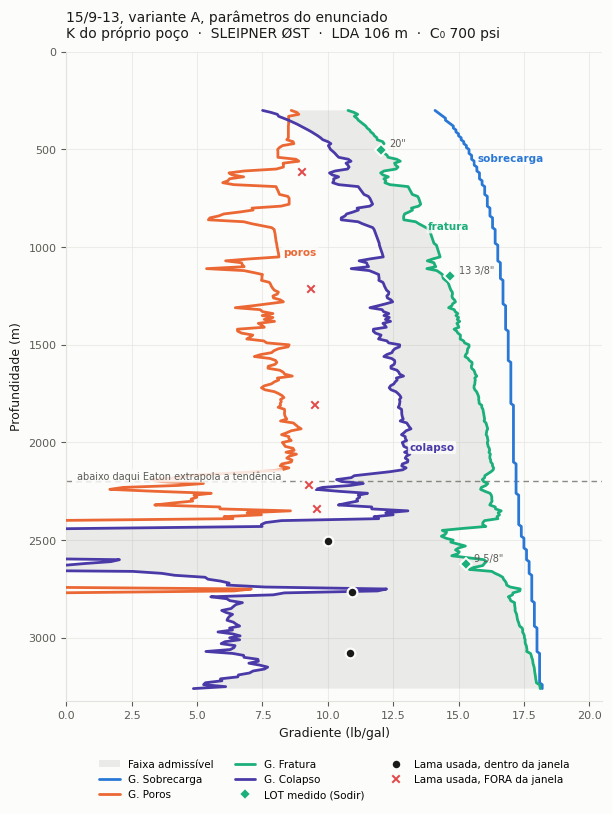

In [ ]:
caso, conf = acha(array, "15/9-13", "A")
explica_e_desenha(caso, conf)

### 15/9-13 — variante B, calibrada

15/9-13 — variante B
  origem do K: LOT do próprio poço
  K dos LOT: 0.522, 0.785, 0.731 (NÃO cresce com a profundidade)
  C0 usado: 7337 psi (recalibrado do peso de lama)
  janela: 340 a 3260 m, 293 pontos
  peso de lama real: 8 de 8 ponto(s) cobertos caem dentro da janela


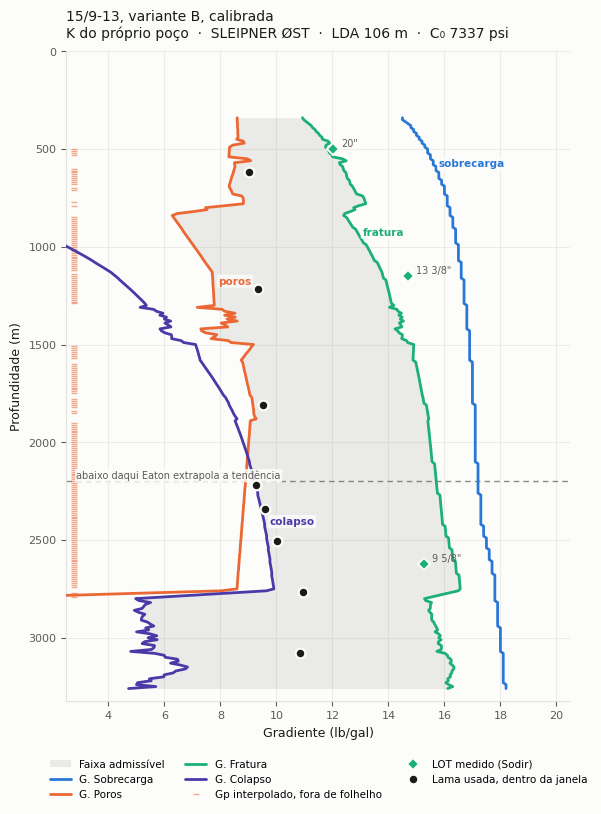

In [ ]:
caso, conf = acha(array, "15/9-13", "B")
explica_e_desenha(caso, conf)

### 15/9-14 — variante A, parâmetros do enunciado

15/9-14 — variante A
  origem do K: LOT do próprio poço
  K dos LOT: 0.750, 0.916 (cresce com a profundidade)
  C0 usado: 700 psi (do enunciado, sem calibrar)
  janela: 640 a 3560 m, 293 pontos
  peso de lama real: 2 de 6 ponto(s) cobertos caem dentro da janela
    fora da janela: 1095 m, lama 9.35 lb/gal (janela 11.22 a 13.39 lb/gal)
    fora da janela: 1515 m, lama 9.60 lb/gal (janela 12.54 a 14.86 lb/gal)
    fora da janela: 1890 m, lama 10.01 lb/gal (janela 12.86 a 15.46 lb/gal)
    fora da janela: 2280 m, lama 10.26 lb/gal (janela 12.88 a 16.03 lb/gal)


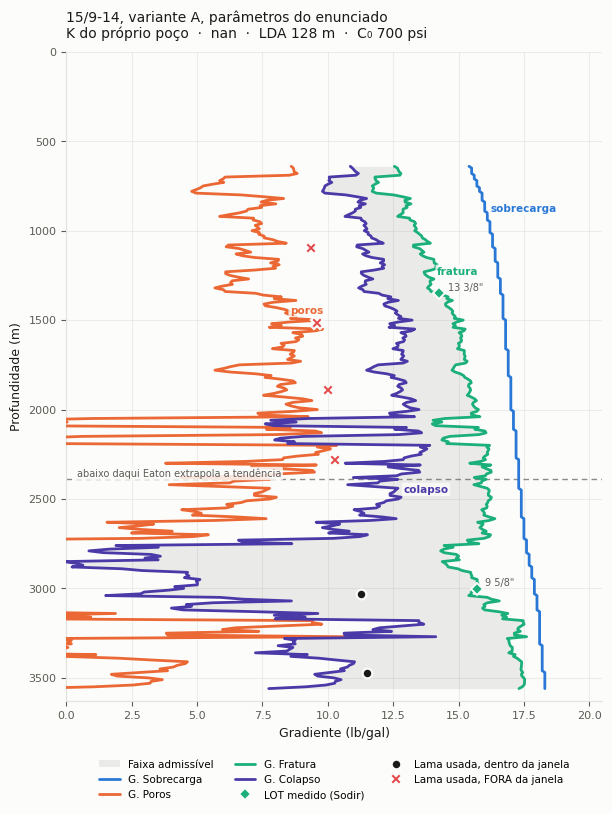

In [ ]:
caso, conf = acha(array, "15/9-14", "A")
explica_e_desenha(caso, conf)

### 15/9-14 — variante B, calibrada

15/9-14 — variante B
  origem do K: LOT do próprio poço
  K dos LOT: 0.696, 0.745 (cresce com a profundidade)
  C0 usado: 6186 psi (recalibrado do peso de lama)
  janela: 870 a 3550 m, 269 pontos
  peso de lama real: 6 de 6 ponto(s) cobertos caem dentro da janela


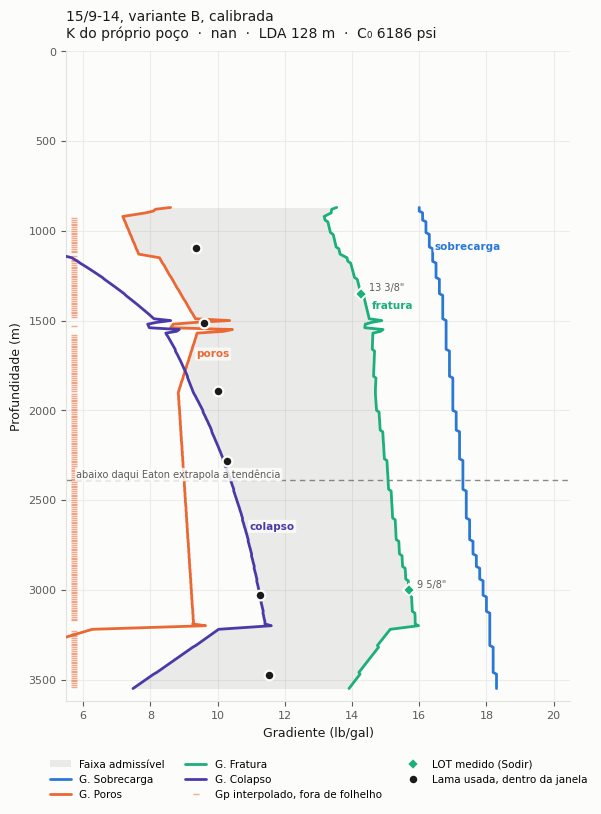

In [ ]:
caso, conf = acha(array, "15/9-14", "B")
explica_e_desenha(caso, conf)

### 15/9-15 — variante A, parâmetros do enunciado

15/9-15 — variante A
  origem do K: LOT do próprio poço
  K dos LOT: 0.865, 0.610, 0.953 (NÃO cresce com a profundidade)
  C0 usado: 700 psi (do enunciado, sem calibrar)
  janela: 450 a 1280 m, 84 pontos
  peso de lama real: 0 de 2 ponto(s) cobertos caem dentro da janela
    fora da janela: 515 m, lama 9.10 lb/gal (janela 11.77 a 8.35 lb/gal)
    fora da janela: 1190 m, lama 9.43 lb/gal (janela 13.22 a 15.83 lb/gal)
  AVISO: o K dos LOT não cresce com a profundidade neste poço. O modelo do enunciado supõe que cresce, a regressão degenera, e a janela inverte em 43 ponto(s). Compare com a janela sintética deste mesmo poço.


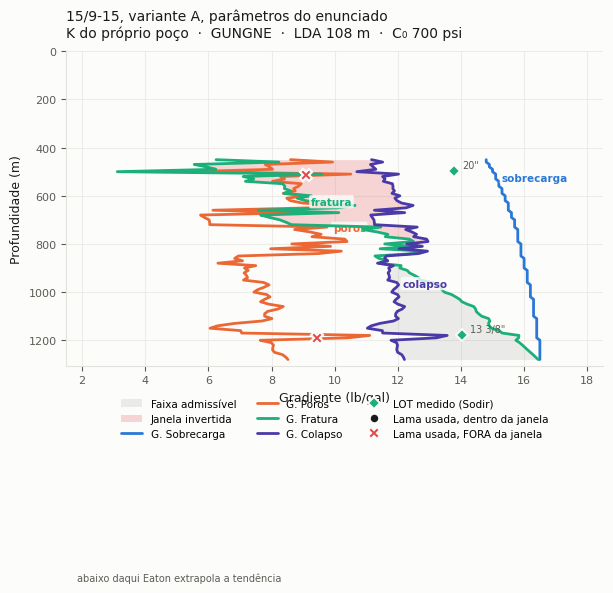

In [ ]:
caso, conf = acha(array, "15/9-15", "A")
explica_e_desenha(caso, conf)

### 15/9-15 — variante B, calibrada

15/9-15 — variante B
  origem do K: LOT do próprio poço
  K dos LOT: 0.821, 0.716, 0.837 (NÃO cresce com a profundidade)
  C0 usado: 2916 psi (recalibrado do peso de lama)
  janela: 450 a 1250 m, 81 pontos
  peso de lama real: 1 de 2 ponto(s) cobertos caem dentro da janela
    fora da janela: 515 m, lama 9.10 lb/gal (janela 8.30 a 4.95 lb/gal)
  AVISO: o K dos LOT não cresce com a profundidade neste poço. O modelo do enunciado supõe que cresce, a regressão degenera, e a janela inverte em 24 ponto(s). Compare com a janela sintética deste mesmo poço.


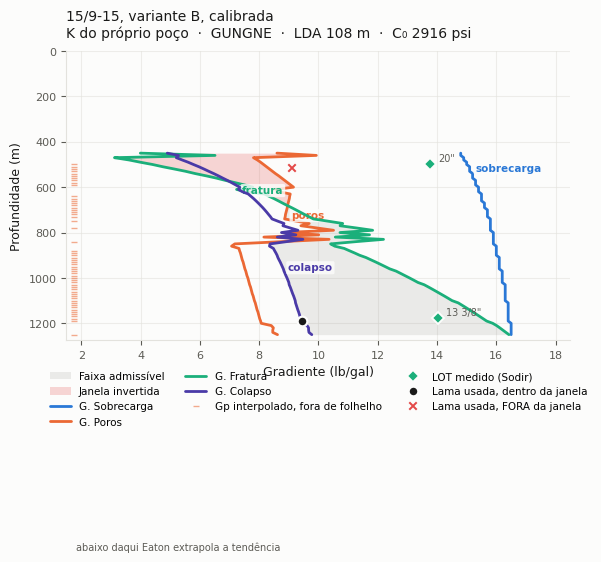

In [ ]:
caso, conf = acha(array, "15/9-15", "B")
explica_e_desenha(caso, conf)

### 15/9-17 — variante A, parâmetros do enunciado

15/9-17 — variante A
  origem do K: LOT do próprio poço
  K dos LOT: 0.803, 0.891, 0.807 (NÃO cresce com a profundidade)
  C0 usado: 700 psi (do enunciado, sem calibrar)
  janela: 650 a 3110 m, 247 pontos
  peso de lama real: 2 de 5 ponto(s) cobertos caem dentro da janela
    fora da janela: 725 m, lama 9.26 lb/gal (janela 12.44 a 13.89 lb/gal)
    fora da janela: 1535 m, lama 9.43 lb/gal (janela 13.86 a 15.55 lb/gal)
    fora da janela: 2250 m, lama 10.01 lb/gal (janela 12.64 a 15.88 lb/gal)


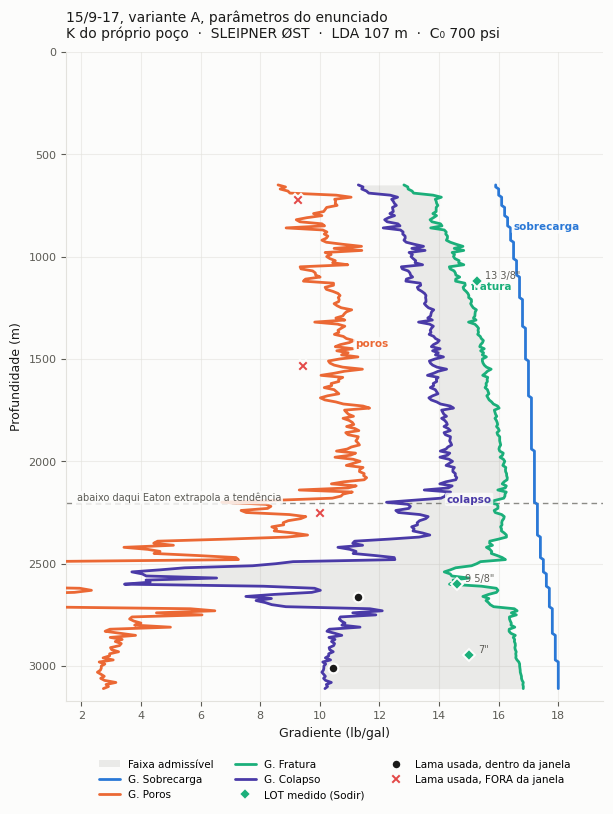

In [ ]:
caso, conf = acha(array, "15/9-17", "A")
explica_e_desenha(caso, conf)

### 15/9-17 — variante B, calibrada

15/9-17 — variante B
  origem do K: LOT do próprio poço
  K dos LOT: 0.495, 0.840, 0.806, 0.833 (NÃO cresce com a profundidade)
  C0 usado: 4387 psi (recalibrado do peso de lama)
  janela: 450 a 3110 m, 267 pontos
  peso de lama real: 5 de 5 ponto(s) cobertos caem dentro da janela


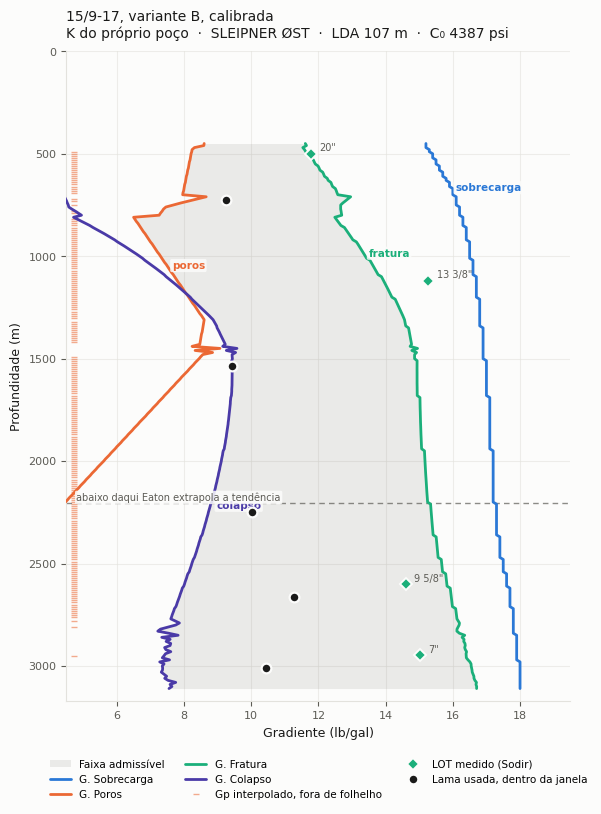

In [ ]:
caso, conf = acha(array, "15/9-17", "B")
explica_e_desenha(caso, conf)

### 15/9-23 — variante A, parâmetros do enunciado

15/9-23 — variante A
  origem do K: LOT do próprio poço
  K dos LOT: 0.728, 0.920, 0.912 (NÃO cresce com a profundidade)
  C0 usado: 700 psi (do enunciado, sem calibrar)
  janela: 540 a 3190 m, 266 pontos
  peso de lama real: 1 de 6 ponto(s) cobertos caem dentro da janela
    fora da janela: 547 m, lama 10.01 lb/gal (janela 10.54 a 13.69 lb/gal)
    fora da janela: 714 m, lama 10.43 lb/gal (janela 10.73 a 13.93 lb/gal)
    fora da janela: 1145 m, lama 10.18 lb/gal (janela 11.96 a 15.15 lb/gal)
    fora da janela: 1380 m, lama 10.01 lb/gal (janela 12.52 a 15.63 lb/gal)
    fora da janela: 3004 m, lama 11.27 lb/gal (janela 15.23 a 17.80 lb/gal)


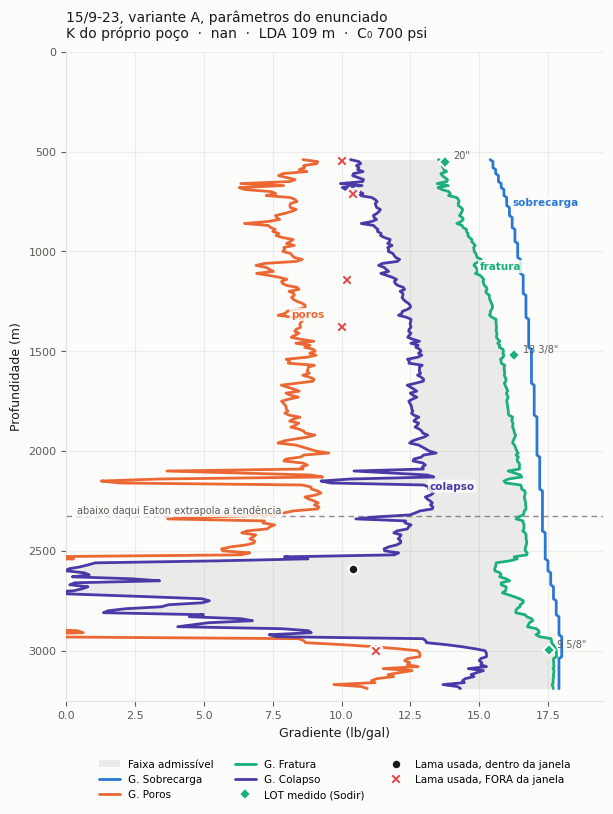

In [ ]:
caso, conf = acha(array, "15/9-23", "A")
explica_e_desenha(caso, conf)

### 15/9-23 — variante B, calibrada

15/9-23 — variante B
  origem do K: LOT do próprio poço
  K dos LOT: 0.732, 0.923, 0.917 (NÃO cresce com a profundidade)
  C0 usado: 8932 psi (recalibrado do peso de lama)
  janela: 450 a 3080 m, 264 pontos
  peso de lama real: 6 de 7 ponto(s) cobertos caem dentro da janela
    fora da janela: 3004 m, lama 11.27 lb/gal (janela 12.44 a 17.81 lb/gal)


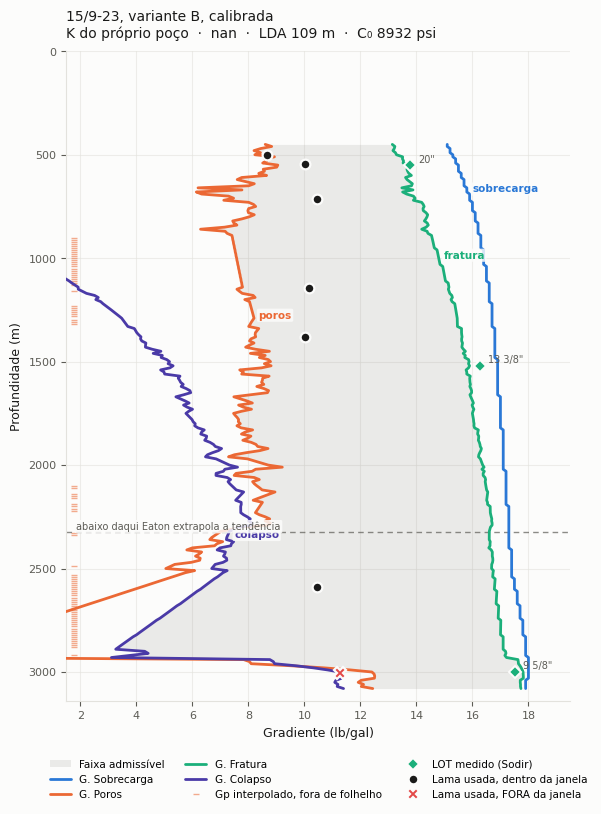

In [ ]:
caso, conf = acha(array, "15/9-23", "B")
explica_e_desenha(caso, conf)

### 15/9-13 — janela sintética (K dos quatro vizinhos)

15/9-13 — janela SINTÉTICA, K de 15/9-14, 15/9-15, 15/9-17, 15/9-23
  origem do K: LOT dos vizinhos: 15/9-14, 15/9-15, 15/9-17, 15/9-23
  K dos LOT: 0.821, 0.495, 0.732, 0.840, 0.716, 0.696, 0.923, 0.837, 0.806, 0.833, 0.745, 0.917 (NÃO cresce com a profundidade)
  C0 usado: 7026 psi (recalibrado do peso de lama)
  janela: 340 a 2910 m, 258 pontos
  peso de lama real: 7 de 7 ponto(s) cobertos caem dentro da janela


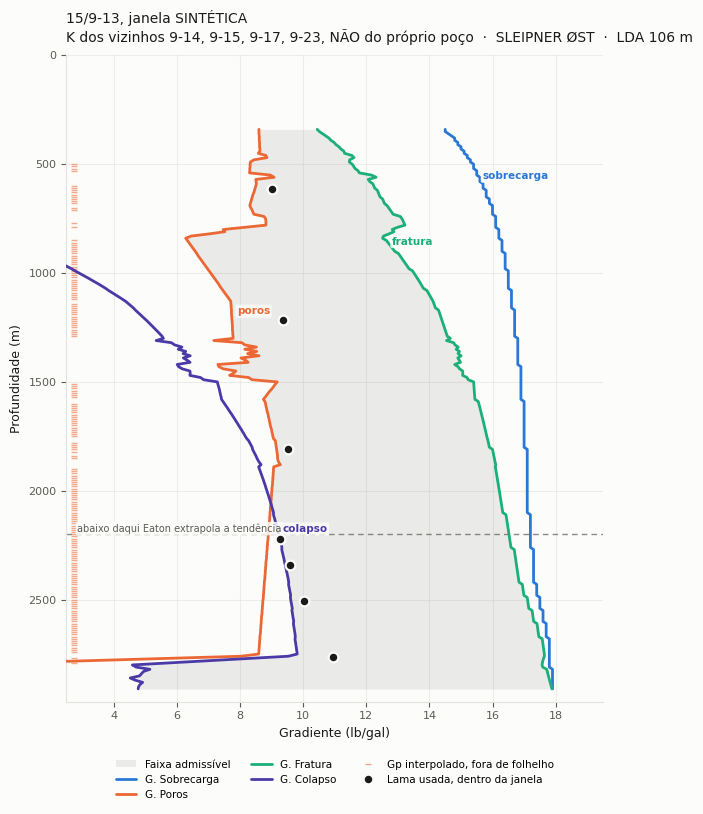

In [ ]:
caso, conf = acha(array, "15/9-13", "sintética")
explica_e_desenha(caso, conf)

### 15/9-14 — janela sintética (K dos quatro vizinhos)

15/9-14 — janela SINTÉTICA, K de 15/9-13, 15/9-15, 15/9-17, 15/9-23
  origem do K: LOT dos vizinhos: 15/9-13, 15/9-15, 15/9-17, 15/9-23
  K dos LOT: 0.821, 0.495, 0.522, 0.732, 0.840, 0.785, 0.716, 0.923, 0.837, 0.806, 0.731, 0.833, 0.917 (NÃO cresce com a profundidade)
  C0 usado: 5371 psi (recalibrado do peso de lama)
  janela: 870 a 2960 m, 210 pontos
  peso de lama real: 4 de 4 ponto(s) cobertos caem dentro da janela


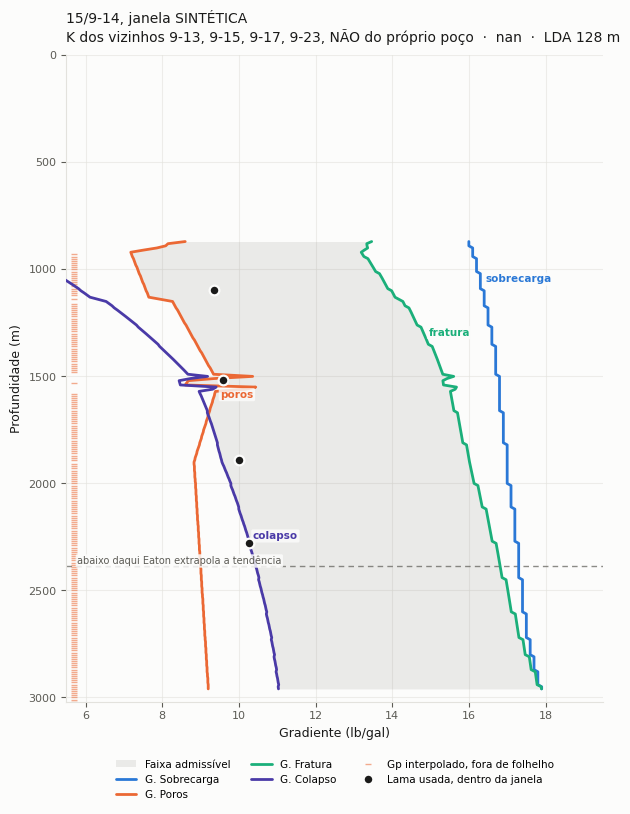

In [ ]:
caso, conf = acha(array, "15/9-14", "sintética")
explica_e_desenha(caso, conf)

### 15/9-15 — janela sintética (K dos quatro vizinhos)

15/9-15 — janela SINTÉTICA, K de 15/9-13, 15/9-14, 15/9-17, 15/9-23
  origem do K: LOT dos vizinhos: 15/9-13, 15/9-14, 15/9-17, 15/9-23
  K dos LOT: 0.495, 0.522, 0.732, 0.840, 0.785, 0.696, 0.923, 0.806, 0.731, 0.833, 0.745, 0.917 (NÃO cresce com a profundidade)
  C0 usado: 5185 psi (recalibrado do peso de lama)
  janela: 450 a 2800 m, 236 pontos
  peso de lama real: 6 de 6 ponto(s) cobertos caem dentro da janela


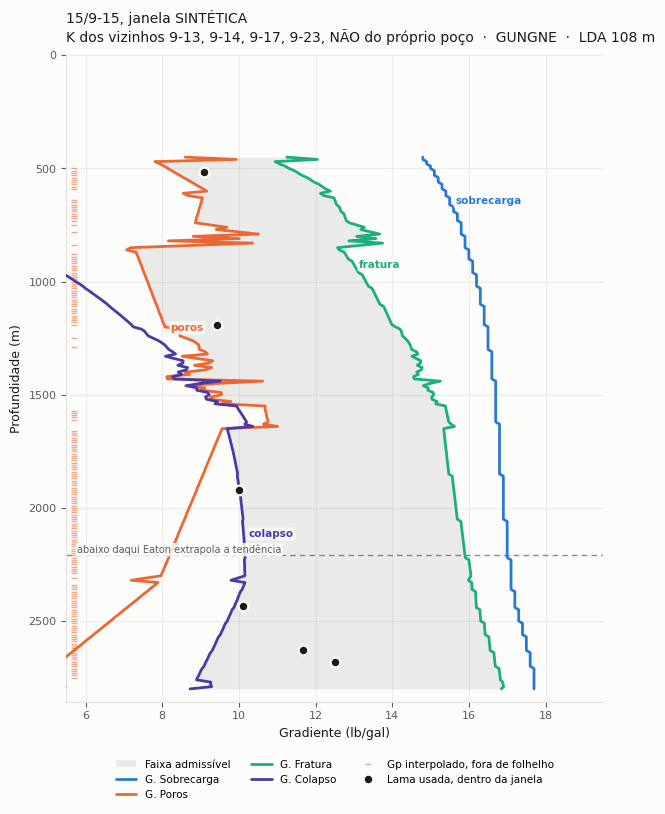

In [ ]:
caso, conf = acha(array, "15/9-15", "sintética")
explica_e_desenha(caso, conf)

### 15/9-17 — janela sintética (K dos quatro vizinhos)

15/9-17 — janela SINTÉTICA, K de 15/9-13, 15/9-14, 15/9-15, 15/9-23
  origem do K: LOT dos vizinhos: 15/9-13, 15/9-14, 15/9-15, 15/9-23
  K dos LOT: 0.821, 0.522, 0.732, 0.785, 0.716, 0.696, 0.923, 0.837, 0.731, 0.745, 0.917 (NÃO cresce com a profundidade)
  C0 usado: 4251 psi (recalibrado do peso de lama)
  janela: 450 a 2630 m, 219 pontos
  peso de lama real: 3 de 3 ponto(s) cobertos caem dentro da janela


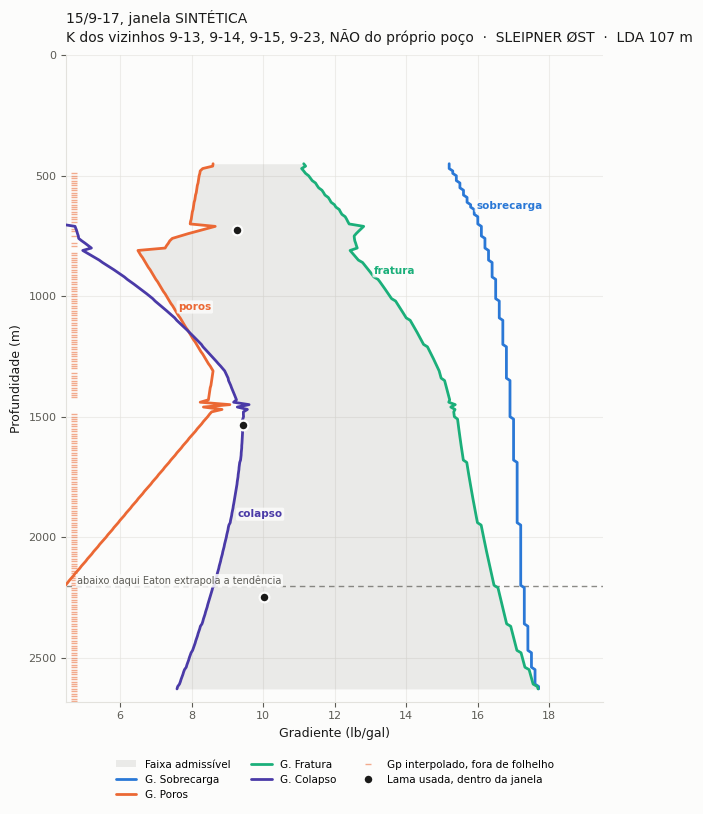

In [ ]:
caso, conf = acha(array, "15/9-17", "sintética")
explica_e_desenha(caso, conf)

### 15/9-23 — janela sintética (K dos quatro vizinhos)

15/9-23 — janela SINTÉTICA, K de 15/9-13, 15/9-14, 15/9-15, 15/9-17
  origem do K: LOT dos vizinhos: 15/9-13, 15/9-14, 15/9-15, 15/9-17
  K dos LOT: 0.821, 0.495, 0.522, 0.840, 0.785, 0.716, 0.696, 0.837, 0.806, 0.731, 0.833, 0.745 (NÃO cresce com a profundidade)
  C0 usado: 8961 psi (recalibrado do peso de lama)
  janela: 450 a 3080 m, 264 pontos
  peso de lama real: 6 de 7 ponto(s) cobertos caem dentro da janela
    fora da janela: 3004 m, lama 11.27 lb/gal (janela 12.44 a 17.75 lb/gal)


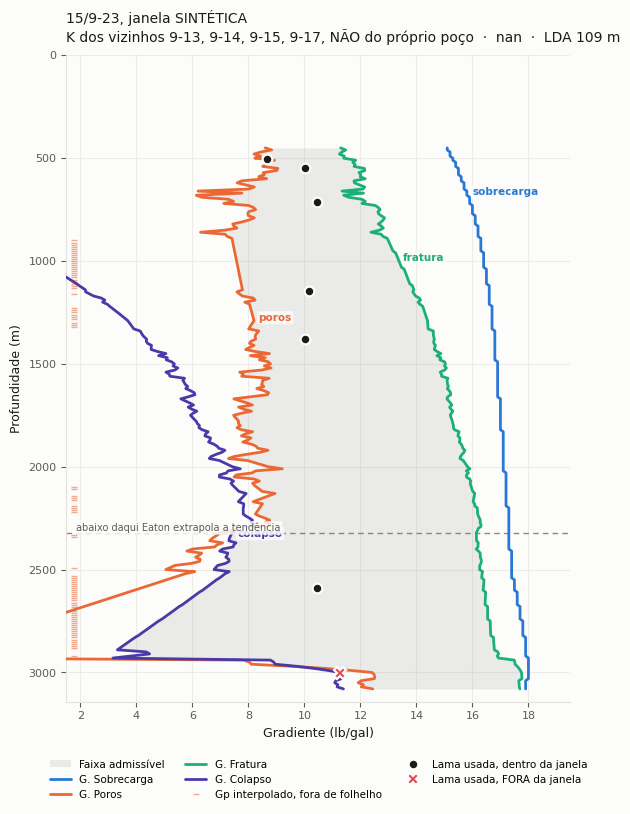

In [ ]:
caso, conf = acha(array, "15/9-23", "sintética")
explica_e_desenha(caso, conf)

## 7. Os quatro painéis de conjunto

As mesmas 15 janelas, agora lado a lado em eixos compartilhados, que é onde
a diferença de largura entre poços fica visível.

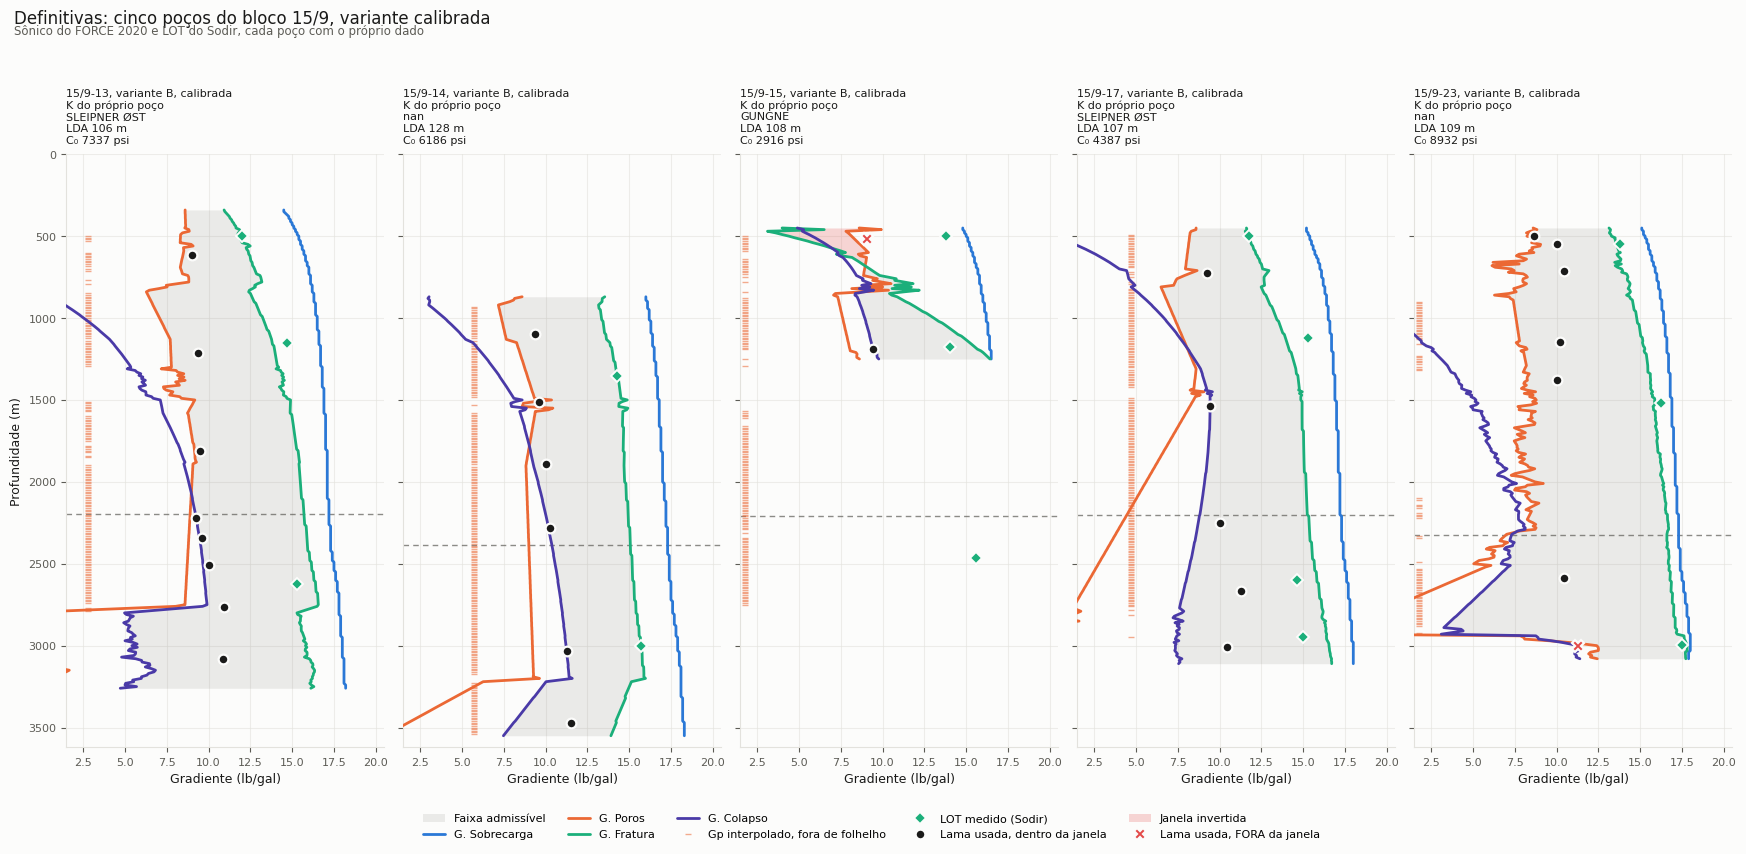

In [ ]:
por = {(c["poço"], c["variante"]): (c, f)
       for c, f in zip(array["casos"], array["conferencias"])}

b = [por[(p, "B")] for p in POCOS if (p, "B") in por]
painel([x[0] for x in b], [x[1] for x in b],
       "Definitivas: cinco poços do bloco 15/9, variante calibrada",
       os.path.join(PASTA_SAIDA_NB, "painel_definitivas_B.png"),
       "Sônico do FORCE 2020 e LOT do Sodir, cada poço com o próprio dado")

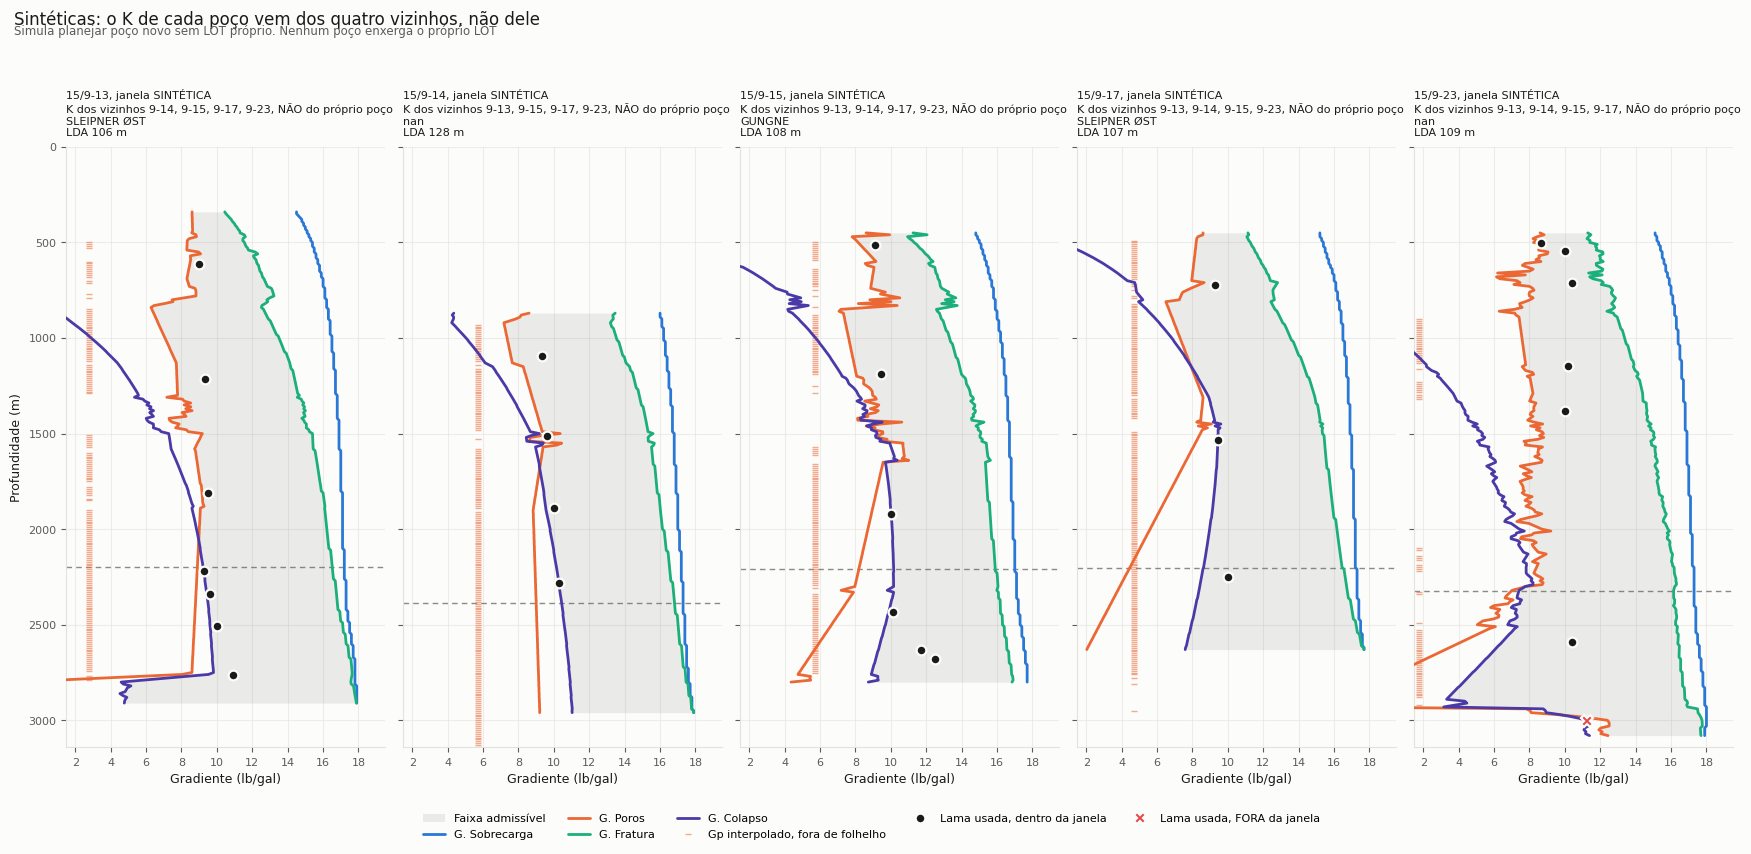

In [ ]:
s = [por[(p, "sintética")] for p in POCOS if (p, "sintética") in por]
painel([x[0] for x in s], [x[1] for x in s],
       "Sintéticas: o K de cada poço vem dos quatro vizinhos, não dele",
       os.path.join(PASTA_SAIDA_NB, "painel_sinteticas.png"),
       "Simula planejar poço novo sem LOT próprio. Nenhum poço enxerga o próprio LOT")

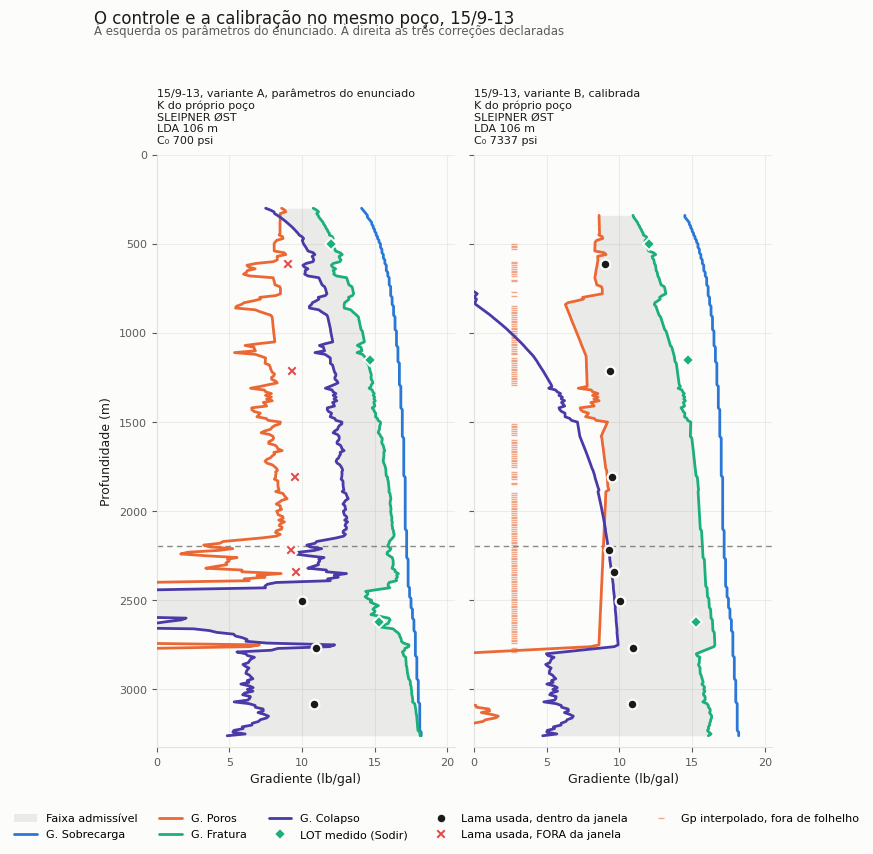

In [ ]:
ab = [por[("15/9-13", "A")], por[("15/9-13", "B")]]
painel([x[0] for x in ab], [x[1] for x in ab],
       "O controle e a calibração no mesmo poço, 15/9-13",
       os.path.join(PASTA_SAIDA_NB, "painel_A_contra_B_15_9-13.png"),
       "À esquerda os parâmetros do enunciado. À direita as três correções declaradas")

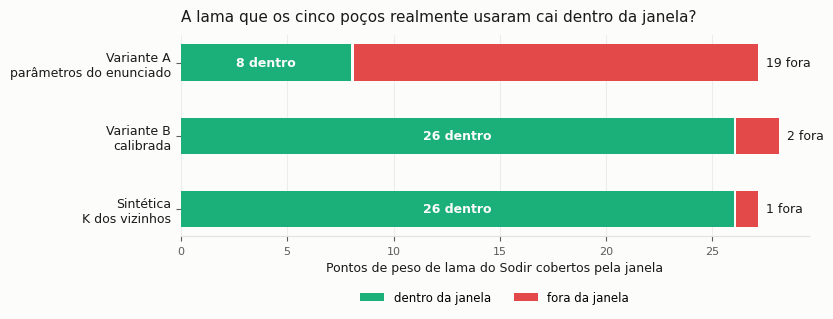

In [ ]:
placar(array, os.path.join(PASTA_SAIDA_NB, "placar_lama.png"))

## 8. Tabela de parâmetros por caso

Uma linha por caso, os parâmetros que definem a janela: tendência normal,
GN, C₀, os coeficientes da regressão de K e os limites da própria janela.

In [ ]:
def _tabela_parametros(array: dict) -> pd.DataFrame:
    """
    Uma linha por caso, só os parâmetros do modelo, sem as colunas de
    diagnóstico do `janelas_resumo.csv`. É o apêndice que junta numa tabela
    só o que hoje está espalhado em prosa nas seções 4, 6 e 7 do relatório.
    """
    linhas = []
    for c in array["casos"]:
        jan = c["janela"]
        d_fra = c["diag"]["fratura"]
        corte = c["máscara"]["corte_gr"]
        linhas.append({
            "poço": c["poço"], "variante": c["variante"],
            "LDA (m)": c["LDA"],
            "corte de GR (API)": "sem corte" if corte is None else corte,
            "d_trend0 (m)": c["tendência"]["d0"],
            "d_trend1 (m)": c["tendência"]["d1"],
            "m da tendência": "%.8f" % c["tendência"]["m_par"],
            "GN (lb/gal)": round(c["diag"]["poros"]["GN"], 4),
            "n de Eaton": c["diag"]["poros"]["n_eaton"],
            "C0 (psi)": round(c["C0"]["c0_usado"], 1),
            "origem do K": c["origem_do_K"],
            "a da regressão K": "%.6f" % d_fra["a_reg"],
            "b da regressão K": "%.6f" % d_fra["b_reg"],
            "D min janela (m)": float(jan["Profundidade"].min()),
            "D max janela (m)": float(jan["Profundidade"].max()),
            "n pontos": int(len(jan)),
        })
    return pd.DataFrame(linhas)

parametros = _tabela_parametros(array)
parametros.to_csv(os.path.join(PASTA_SAIDA_NB, "parametros_por_caso.csv"), index=False)
parametros

,poço,variante,LDA (m),corte de GR (API),d_trend0 (m),d_trend1 (m),m da tendência,GN (lb/gal),n de Eaton,C0 (psi),origem do K,a da regressão K,b da regressão K,D min janela (m),D max janela (m),n pontos
0,15/9-13,A,106.0,sem corte,300.0,1990.0,-0.00003528,8.5959,2.0,700.0,LOT do próprio poço,4.632550,3.437948,300.0,3260.0,297
1,15/9-13,B,106.0,75.0,340.0,1380.0,-0.00004758,8.5955,2.0,7336.6,LOT do próprio poço,5.147767,3.423406,340.0,3260.0,293
2,15/9-14,A,128.0,sem corte,640.0,1980.0,-0.00007279,8.5961,2.0,700.0,LOT do próprio poço,5.135227,3.259905,640.0,3560.0,293
3,15/9-14,B,128.0,75.0,870.0,1540.0,-0.00005807,8.5955,2.0,6185.8,LOT do próprio poço,17.481366,-5.066048,870.0,3550.0,269
4,15/9-15,A,108.0,sem corte,450.0,1760.0,-0.00005574,8.5959,2.0,700.0,LOT do próprio poço,0.896849,6.175900,450.0,1280.0,84
5,15/9-15,B,108.0,75.0,450.0,1400.0,-0.00007015,8.5954,2.0,2915.7,LOT do próprio poço,0.695501,6.351599,450.0,1250.0,81
6,15/9-17,A,107.0,sem corte,650.0,2190.0,-0.00003397,8.5954,2.0,700.0,LOT do próprio poço,4.962313,3.427285,650.0,3110.0,247
7,15/9-17,B,107.0,75.0,450.0,1310.0,-0.00005837,8.5962,2.0,4387.0,LOT do próprio poço,4.628321,3.727370,450.0,3110.0,267
8,15/9-23,A,109.0,sem corte,540.0,2090.0,-0.00005649,8.5954,2.0,700.0,LOT do próprio poço,7.965456,0.304076,540.0,3190.0,266
9,15/9-23,B,109.0,75.0,450.0,1470.0,-0.00005206,8.5957,2.0,8932.3,LOT do próprio poço,7.989628,0.253444,450.0,3080.0,264


## 9. Exportar dados da janela operacional

**Aqui para assim que essa célula for rodada na aba da esquerda terá uma pasta chamada "Saída" nela contem os csv com as janelas operacionais por poço e por variação**

In [ ]:
import os

# Define the columns to export
export_columns = [
    "Profundidade",
    "Gradiente de Sobrecarga",
    "Gradiente de Poros",
    "Gradiente de Fratura",
    "Gradiente de Colapso",
    "Limite inferior",
    "Limite superior",
    "Largura da janela"
]

# Iterate through each case and export the operational window data
for caso in array["casos"]:
    poco = caso["poço"]
    variante = caso["variante"]
    janela_df = caso["janela"]

    # Ensure all export_columns exist in the DataFrame
    columns_to_export = [col for col in export_columns if col in janela_df.columns]

    # Create a clean filename
    filename = f"janela_{poco.replace('/', '_')}_{variante}.csv"
    filepath = os.path.join(PASTA_SAIDA_NB, filename)

    # Save the DataFrame to CSV
    janela_df[columns_to_export].to_csv(filepath, index=False)
    print(f"Exported operational window for {poco} ({variante}) to {filepath}")

print("All operational window data exported successfully.")

Exported operational window for 15/9-13 (A) to saida/janela_15_9-13_A.csv
Exported operational window for 15/9-13 (B) to saida/janela_15_9-13_B.csv
Exported operational window for 15/9-14 (A) to saida/janela_15_9-14_A.csv
Exported operational window for 15/9-14 (B) to saida/janela_15_9-14_B.csv
Exported operational window for 15/9-15 (A) to saida/janela_15_9-15_A.csv
Exported operational window for 15/9-15 (B) to saida/janela_15_9-15_B.csv
Exported operational window for 15/9-17 (A) to saida/janela_15_9-17_A.csv
Exported operational window for 15/9-17 (B) to saida/janela_15_9-17_B.csv
Exported operational window for 15/9-23 (A) to saida/janela_15_9-23_A.csv
Exported operational window for 15/9-23 (B) to saida/janela_15_9-23_B.csv
Exported operational window for 15/9-13 (sintética) to saida/janela_15_9-13_sintética.csv
Exported operational window for 15/9-14 (sintética) to saida/janela_15_9-14_sintética.csv
Exported operational window for 15/9-15 (sintética) to saida/janela_15_9-15_sint

## 10. O que este notebook não resolve

- Nenhum dos cinco poços tem ponto de pressão medido: o gradiente de poros
  normal (8,596 lb/gal) é só uma premissa, não é medida. Varrer de 8,50 a 8,70 não muda nenhum veredito contra a lama real.
- O C₀ recalculado é o menor valor compatível com o poço não ter
  desmoronado, um limite inferior aparente, não resistência medida em
  laboratório.
- Aqui não está sendo considerado nada do Pre-sal
- O preparo do dado (download do Sodir e do FORCE 2020, parsing do LAS,
  preenchimento de buraco por análogo) não está neste Colab, foi feito em outro notebook: ele já aconteceu, uma vez, para gerar os 4 CSV da sessão 1. Ou seja, inputs tratados já